# **Проектная работа №5. Анализ динамики изменений земного покрова на последовательности разновременных спутниковых снимков с использованием спектральных индексов**

## **1. Цель работы**

Выполнить количественный анализ динамики изменения классов земного покрова на выбранной территории за период с 2019 по 2024 год на основе разновременных спутниковых снимков Sentinel-2 и провести сравнительную оценку результатов, полученных методом пороговой сегментации на основе спектральных индексов и с использованием готовых карт классификации Dynamic World.

## **2. Задачи работы**

1.  **Подготовить** последовательность разновременных снимков (снимки Sentinel-2 и карты Dynamic World) за 2019-2024 гг.;
2.  **Классифицировать** земной покров на снимках Sentinel-2, применив метод пороговой сегментации по спектральным индексам;
3.  **Рассчитать и сравнить** количественные показатели динамики (площади, темпы роста) для двух методов классификации: по индексам и по данным Dynamic World;
4.  **Оценить** выявленные тренды изменения покрова и **сформулировать** выводы о сопоставимости результатов двух методов анализа.

## **3. Загрузка данных для анализа из Google Earth Engine**

> **Примечание.** В качестве примера реализации можно использовать код из лекционных материалов, доступный по ссылке: https://u.to/nWdJIg. Для выполнения текущей работы актуальны только **Раздел 1** и **Раздел 2** указанного источника.





### **3.1. Настройка рабочей среды и аутентификация**

In [2]:
# Установка зависимостей (выполняется однократно):
# !pip install -U earthengine-api geemap geedim rasterio

import os
import logging
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm, TwoSlopeNorm, LogNorm
from matplotlib.patches import Patch
import rasterio
from rasterio.warp import transform as warp_transform
import ee
import geemap

# geemap/geedim выводят предупреждения об устаревших API и переполнении пула соединений —
# на результат они не влияют, поэтому скрываем их
warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', message='.*STAC.*')
logging.getLogger('urllib3.connectionpool').setLevel(logging.ERROR)

# Аутентификация: при первом запуске открывается браузер для входа в Google-аккаунт,
# токен сохраняется в ~/.config/earthengine/credentials, и при повторных запусках вход не нужен
ee.Authenticate()

# Инициализация с проектом Google Cloud, в котором включен Earth Engine API
PROJECT_ID = 'test-507512'
ee.Initialize(project=PROJECT_ID)

# Общие параметры работы
YEARS = list(range(2019, 2025))     # 2019–2024
SUMMER = ('06-01', '09-01')          # июнь–август (конечная дата в filterDate не включается)
CLOUD_PERCENTAGE = 20                # порог облачности сцены CLOUDY_PIXEL_PERCENTAGE, %

# Папки для результатов (относительно папки с ноутбуком)
DATA_DIR = 'data'                    # растры, экспортированные из GEE
INDEX_DIR = 'indices'                # спектральные индексы, по папкам лет
SEG_DIR = 'segmentation'             # результаты пороговой сегментации
RESULTS_DIR = 'results'              # итоговые таблицы
for folder in (DATA_DIR, INDEX_DIR, SEG_DIR, RESULTS_DIR):
    os.makedirs(folder, exist_ok=True)

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 40)
plt.rcParams.update({'figure.dpi': 80, 'axes.titlesize': 11, 'axes.spines.top': False,
                     'axes.spines.right': False})

print(f"earthengine-api {ee.__version__}, geemap {geemap.__version__}, rasterio {rasterio.__version__}")
print(f"Earth Engine инициализирован, проект: {PROJECT_ID}")

earthengine-api 1.7.53, geemap 0.39.0, rasterio 1.5.2
Earth Engine инициализирован, проект: test-507512


### **3.2. Определение области интереса**

- Выберите территорию размером не менее 10×10 км (100 км²) с разнообразным земным покровом
- Обязательно должны присутствовать: водные объекты, растительность, застройка, открытая почва
- Зафиксируйте координаты углов ROI для воспроизводимости результатов

In [3]:
# Область интереса: г. Павловский Посад (Московская обл.) и окрестности.
# На участке есть все требуемые типы покрова:
#   вода           — реки Клязьма и Вохна, пруды, затопленные торфяные карьеры;
#   растительность — смешанные и хвойные леса, луга, поймы;
#   застройка      — Павловский Посад, пригородные поселки и садовые товарищества;
#   открытая почва — пашни, карьеры, строительные площадки.
#
# ROI задан прямоугольником в метрической проекции UTM зоны 37N (EPSG:32637). Границы кратны 10 м,
# поэтому при экспорте с шагом 10 м сетка пикселей точно совпадает с границами ROI: в растрах нет
# пустых углов, все пиксели — ровно 10×10 м, а снимки и карты всех лет ложатся на одну сетку.
ROI_CRS = 'EPSG:32637'
ROI_BOUNDS = [471700, 6176800, 485700, 6188800]   # [xmin, ymin, xmax, ymax], м

roi = ee.Geometry.Rectangle(ROI_BOUNDS, proj=ROI_CRS, geodesic=False)

xmin, ymin, xmax, ymax = ROI_BOUNDS
ROI_WIDTH_KM, ROI_HEIGHT_KM = (xmax - xmin) / 1000, (ymax - ymin) / 1000
EXTENT_KM = [0, ROI_WIDTH_KM, 0, ROI_HEIGHT_KM]   # оси карт: км от юго-западного угла ROI

# Координаты углов ROI в UTM и в географических координатах WGS 84 (для воспроизводимости)
corner_x = [xmin, xmax, xmax, xmin]
corner_y = [ymin, ymin, ymax, ymax]
corner_lon, corner_lat = warp_transform(ROI_CRS, 'EPSG:4326', corner_x, corner_y)
roi_corners = pd.DataFrame({
    'Угол ROI': ['Юго-западный', 'Юго-восточный', 'Северо-восточный', 'Северо-западный'],
    'X (UTM 37N), м': corner_x,
    'Y (UTM 37N), м': corner_y,
    'Долгота, °': np.round(corner_lon, 5),
    'Широта, °': np.round(corner_lat, 5),
})
display(roi_corners)
print(f"Размер ROI: {ROI_WIDTH_KM:.0f} × {ROI_HEIGHT_KM:.0f} км, площадь {ROI_WIDTH_KM * ROI_HEIGHT_KM:.0f} км²")

# Центр города: от него далее описывается положение участков с изменениями
TOWN_CENTER = (38.650, 55.783)   # долгота, широта
town_x, town_y = warp_transform('EPSG:4326', ROI_CRS, [TOWN_CENTER[0]], [TOWN_CENTER[1]])
TOWN_KM = ((town_x[0] - xmin) / 1000, (town_y[0] - ymin) / 1000)
print(f"Центр Павловского Посада: {TOWN_KM[0]:.1f} км к востоку и {TOWN_KM[1]:.1f} км к северу от ЮЗ угла ROI")

# Граница ROI на интерактивной карте (контур шириной 3 пикселя)
roi_outline = ee.Image().byte().paint(ee.FeatureCollection([ee.Feature(roi)]), 1, 3)

map_roi = geemap.Map()
map_roi.add_basemap('Esri.WorldImagery')
map_roi.centerObject(roi, 12)
map_roi.addLayer(roi_outline, {'palette': ['ff0000']}, 'Область интереса')
map_roi

,Угол ROI,"X (UTM 37N), м","Y (UTM 37N), м","Долгота, °","Широта, °"
0,Юго-западный,471700,6176800,38.54930,55.73609
1,Юго-восточный,485700,6176800,38.77226,55.73671
2,Северо-восточный,485700,6188800,38.77163,55.84453
3,Северо-западный,471700,6188800,38.54806,55.84391


Размер ROI: 14 × 12 км, площадь 168 км²
Центр Павловского Посада: 6.3 км к востоку и 5.2 км к северу от ЮЗ угла ROI


Map(center=[55.790361120510234, 38.660313698606586], controls=(WidgetControl(options=['position', 'transparent…

### **3.3. Функции для загрузки и обработки данных Sentinel-2**

In [4]:
def load_sentinel2_collection(roi, start_date, end_date, cloud_percentage=20):
    """
    Загружает и фильтрует коллекцию снимков Sentinel-2 уровня 2A (лекция, раздел 2.2).

    Параметры:
        roi (ee.Geometry): область интереса
        start_date, end_date (str): период 'YYYY-MM-DD' (конечная дата не включается)
        cloud_percentage (int): максимальный процент облачности сцены

    Возвращает:
        ee.ImageCollection: снимки с замаскированными облаками и тенями,
                            значения отражения приведены к диапазону 0–1
    """
    collection = (ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')
                  .filterBounds(roi)                       # снимки, покрывающие ROI
                  .filterDate(start_date, end_date)        # снимки за период
                  .filter(ee.Filter.lessThan('CLOUDY_PIXEL_PERCENTAGE', cloud_percentage)))

    def mask_clouds(image):
        """Маскирует облака и тени по каналу SCL (Scene Classification Layer)."""
        scl = image.select('SCL')
        # 3 — тени облаков, 8 и 9 — облака средней и высокой вероятности, 10 — перистые облака
        mask = scl.neq(3).And(scl.neq(8)).And(scl.neq(9)).And(scl.neq(10))
        # Sentinel-2 хранит отражение, умноженное на 10000 → переводим в 0–1
        return (image.select('B.*').updateMask(mask).divide(10000)
                .copyProperties(image, ['system:time_start']))

    return collection.map(mask_clouds)


def create_median_composite(collection, roi):
    """
    Создает медианный композит (лекция, раздел 2.3): медиана по каждому пикселю
    устойчива к остаткам облаков и теней, пропущенным маской.
    """
    return collection.median().clip(roi)


def collection_info(collection, roi):
    """
    Возвращает даты съемки снимков коллекции и статистику числа безоблачных
    наблюдений на пиксель (минимум, среднее, максимум по ROI).
    """
    dates = collection.aggregate_array('system:time_start').map(
        lambda t: ee.Date(t).format('dd.MM')).getInfo()
    clear_count = collection.select('B8').count().unmask(0)
    stats = clear_count.reduceRegion(
        reducer=ee.Reducer.minMax().combine(ee.Reducer.mean(), sharedInputs=True),
        geometry=roi, scale=20, crs=ROI_CRS, maxPixels=1e9).getInfo()
    return dates, stats

### **3.4. Создание медианных композитов за летние периоды 2019-2024**

- Используйте медиану для минимизации влияния облачности
- Фильтрация по облачности: CLOUDY_PIXEL_PERCENTAGE < 20%
- Маскирование облаков и теней по каналу SCL (см. лекцию, раздел 2.2)


In [5]:
# Каналы для экспорта: их достаточно для расчета всех 8 индексов таблицы 1
# (B2 — синий, B3 — зеленый, B4 — красный, B8 — ближний ИК, B11 и B12 — коротковолновый ИК)
S2_BANDS = ['B2', 'B3', 'B4', 'B8', 'B11', 'B12']

s2_composites = {}
info_rows = []
for year in YEARS:
    start, end = f'{year}-{SUMMER[0]}', f'{year}-{SUMMER[1]}'
    collection = load_sentinel2_collection(roi, start, end, CLOUD_PERCENTAGE)
    s2_composites[year] = create_median_composite(collection, roi).select(S2_BANDS)

    dates, clear = collection_info(collection, roi)
    unique_dates = sorted(set(dates), key=lambda d: (d[3:], d[:2]))   # по месяцу, затем по дню
    info_rows.append({
        'Год': year,
        'Снимков': len(dates),
        'Дат съемки': len(unique_dates),
        'Даты съемки (дд.мм)': ', '.join(unique_dates),
        'Наблюдений на пиксель: мин': clear['B8_min'],
        'сред': round(clear['B8_mean'], 1),
        'макс': clear['B8_max'],
    })

s2_info = pd.DataFrame(info_rows).set_index('Год')
print(f"Медианные композиты Sentinel-2 за лето (июнь–август), облачность сцены < {CLOUD_PERCENTAGE}%:")
display(s2_info)

Медианные композиты Sentinel-2 за лето (июнь–август), облачность сцены < 20%:


,Снимков,Дат съемки,Даты съемки (дд.мм),Наблюдений на пиксель: мин,сред,макс
Год,,,,,,
2019,10,10,"04.06, 06.06, 09.06, 11.06, 19.06, 24.06, 20.0...",5,9.0,10
2020,4,4,"10.06, 18.06, 30.06, 28.07",0,3.6,4
2021,12,12,"03.06, 18.06, 20.06, 23.06, 08.07, 10.07, 13.0...",4,10.8,12
2022,6,6,"08.06, 23.06, 28.06, 30.06, 17.08, 24.08",3,5.9,6
2023,7,7,"08.06, 13.06, 15.06, 18.06, 25.06, 07.08, 17.08",4,6.1,7
2024,9,9,"07.07, 09.07, 17.07, 24.07, 27.07, 16.08, 21.0...",4,7.5,9


### **3.5. Функции для загрузки и обработки данных карт классификации**

**Используйте коллекцию Dynamic World (Google/WRI)**

**Коллекция в GEE:** `ee.ImageCollection("GOOGLE/DYNAMICWORLD/V1")`
- **Период:** с июня 2015 года по настоящее время (обновляется постоянно)
- **Разрешение:** 10 метров
- **Особенности:**
  - Предоставляет вероятности для каждого класса (не жесткую классификацию)
  - Обновляется почти в реальном времени для каждого снимка Sentinel-2
  - 9 классов земного покрова


```python
# Пример загрузки Dynamic World

def load_landcover_data(roi, start_date, end_date, composite='mode'):
    """
    Загружает карты классификации Google Dynamic World (10м).
    
    Классы: 0-Вода, 1-Деревья, 2-Трава, 3-Затопл.растительность,
            4-Культуры, 5-Кустарники, 6-Застройка, 7-Голая земля, 8-Снег/лед
    
    Args:
        roi: область интереса
        start_date, end_date: период 'YYYY-MM-DD'
        composite: 'mode'|'first'|'mosaic'|'collection'
    """
    
    labels = ee.ImageCollection("GOOGLE/DYNAMICWORLD/V1") \
        .filterBounds(roi) \
        .filterDate(start_date, end_date) \
        .select('label')
    
    if composite == 'collection':
        return labels.map(lambda img: img.clip(roi))
    
    return getattr(labels, composite)().clip(roi)

# Загрузка с композитом по моде (наиболее частый класс)
landcover = load_landcover_data(roi, '2024-06-01', '2024-08-31')

# Параметры визуализации для Dynamic World
landcover_vis = {
    'min': 0,
    'max': 8,
    'palette': [
        '419bdf',  # 0 - Вода - синий
        '397d49',  # 1 - Деревья - темно-зеленый  
        '88b053',  # 2 - Трава - светло-зеленый
        '7a87c6',  # 3 - Затопленная растительность - сине-фиолетовый
        'e49635',  # 4 - Культуры - оранжево-желтый
        'dfc35a',  # 5 - Кустарники - песочный
        'c4281b',  # 6 - Застройка - красный
        'a59b8f',  # 7 - Голая земля - серо-коричневый
        'b39fe1'   # 8 - Снег и лед - светло-фиолетовый (для контраста)
    ]
}

# Визуализация на карте
map_dw = geemap.Map()
map_dw.centerObject(roi, 11)
map_dw.addLayer(landcover, landcover_vis, 'Dynamic World')
map_dw

```

In [6]:
# Классы Dynamic World и их цвета (порядок соответствует номеру класса 0–8)
DW_CLASS_NAMES = ['Вода', 'Деревья', 'Трава', 'Затопл. растительность', 'Культуры',
                  'Кустарники', 'Застройка', 'Голая земля', 'Снег и лед']
DW_PALETTE = ['419bdf', '397d49', '88b053', '7a87c6', 'e49635',
              'dfc35a', 'c4281b', 'a59b8f', 'b39fe1']


def load_landcover_data(roi, start_date, end_date, composite='mode'):
    """
    Загружает карты классификации Google Dynamic World (10 м).

    Классы: 0-Вода, 1-Деревья, 2-Трава, 3-Затопл.растительность,
            4-Культуры, 5-Кустарники, 6-Застройка, 7-Голая земля, 8-Снег/лед

    Параметры:
        roi: область интереса
        start_date, end_date: период 'YYYY-MM-DD' (конечная дата не включается)
        composite: 'mode' | 'first' | 'mosaic' | 'collection'
    """
    labels = (ee.ImageCollection('GOOGLE/DYNAMICWORLD/V1')
              .filterBounds(roi)
              .filterDate(start_date, end_date)
              .select('label'))

    if composite == 'collection':
        return labels.map(lambda img: img.clip(roi))

    return getattr(labels, composite)().clip(roi)


landcover_vis = {'min': 0, 'max': 8, 'palette': DW_PALETTE}
S2_VIS = {'bands': ['B4', 'B3', 'B2'], 'min': 0.0, 'max': 0.3, 'gamma': 1.4}

# Проверка: карта Dynamic World (мода за лето 2024) поверх композита Sentinel-2
landcover = load_landcover_data(roi, '2024-06-01', '2024-09-01')

map_dw = geemap.Map()
map_dw.add_basemap('Esri.WorldImagery')
map_dw.centerObject(roi, 12)
map_dw.addLayer(s2_composites[2024], S2_VIS, 'Sentinel-2, лето 2024')
map_dw.addLayer(landcover, landcover_vis, 'Dynamic World, лето 2024')
map_dw.addLayer(roi_outline, {'palette': ['ff0000']}, 'Область интереса')
map_dw.add_legend(title='Dynamic World', legend_dict=dict(zip(DW_CLASS_NAMES, DW_PALETTE)))
map_dw

Map(center=[55.790361120510234, 38.660313698606586], controls=(WidgetControl(options=['position', 'transparent…

### **3.6. Создание карт классификации за летние периоды 2019-2024**

- Для карт классов используйте моду — наиболее частый класс в каждом пикселе (`composite='mode'`): медиана номеров классов не имеет смысла

In [7]:
# Для карт классов берется мода — наиболее частый класс пикселя за лето
# (медиана номеров классов смысла не имеет)
dw_maps = {}
dw_rows = []
for year in YEARS:
    start, end = f'{year}-{SUMMER[0]}', f'{year}-{SUMMER[1]}'
    dw_maps[year] = load_landcover_data(roi, start, end, composite='mode')

    # Сколько карт DW содержат значение в каждом пикселе (облачные пиксели в DW замаскированы)
    dw_collection = load_landcover_data(roi, start, end, composite='collection')
    obs = dw_collection.count().unmask(0).reduceRegion(
        reducer=ee.Reducer.minMax().combine(ee.Reducer.mean(), sharedInputs=True),
        geometry=roi, scale=20, crs=ROI_CRS, maxPixels=1e9).getInfo()
    dw_rows.append({
        'Год': year,
        'Карт Dynamic World': dw_collection.size().getInfo(),
        'Наблюдений на пиксель: мин': obs['label_min'],
        'сред': round(obs['label_mean'], 1),
        'макс': obs['label_max'],
    })

dw_info = pd.DataFrame(dw_rows).set_index('Год')
print("Карты Dynamic World за лето (июнь–август), композит по моде:")
display(dw_info)

Карты Dynamic World за лето (июнь–август), композит по моде:


,Карт Dynamic World,Наблюдений на пиксель: мин,сред,макс
Год,,,,
2019,25,5,6.7,11
2020,22,1,3.5,9
2021,26,5,7.9,12
2022,20,5,6.5,9
2023,19,3,4.7,7
2024,26,7,10.2,15


### **3.7. Экспорт полученных растров**

- **Медианные композиты** Sentinel-2 (6 файлов GeoTIFF):
  - `sentinel2_summer_2019.tif` (июнь-август 2019)
  - `sentinel2_summer_2020.tif` (июнь-август 2020)
  - `sentinel2_summer_2021.tif` (июнь-август 2021)
  - `sentinel2_summer_2022.tif` (июнь-август 2022)
  - `sentinel2_summer_2023.tif` (июнь-август 2023)
  - `sentinel2_summer_2024.tif` (июнь-август 2024)

- **Карты классификации** Dynamic World (6 файлов GeoTIFF):
  - `DYNAMICWORLD_summer_2019.tif` (июнь-август 2019)
  - `DYNAMICWORLD_summer_2020.tif` (июнь-август 2020)
  - `DYNAMICWORLD_summer_2021.tif` (июнь-август 2021)
  - `DYNAMICWORLD_summer_2022.tif` (июнь-август 2022)
  - `DYNAMICWORLD_summer_2023.tif` (июнь-август 2023)
  - `DYNAMICWORLD_summer_2024.tif` (июнь-август 2024)

- Экспорт выполняйте в метрической проекции UTM функцией `export_georeferenced_raster` из лекции: размер пикселя 10×10 м
- Карты Dynamic World экспортируйте с типом `int16`: при типе `uint8` значение 0 используется как «нет данных» и совпадает с классом «Вода»
- Размер пикселя 10 м соответствует собственному разрешению каналов B2, B3, B4 и B8; каналы B11 и B12 (20 м) при экспорте пересчитываются на ту же сетку. Если экспорт идёт слишком долго, увеличьте `scale` (например, до 20 или 30 м): площади в разделе 6 рассчитываются по размеру пикселя из растра

In [8]:
def utm_crs(roi):
    """
    Возвращает код EPSG зоны UTM, в которую попадает центр области интереса (лекция, раздел 2.4).
    """
    lon, lat = roi.centroid(maxError=1).coordinates().getInfo()
    zone = int((lon + 180) // 6) + 1
    return f'EPSG:{(32600 if lat >= 0 else 32700) + zone}'


def export_georeferenced_raster(image, roi, filename, scale=10, dtype='float32', tile_size=256):
    """
    Экспортирует изображение Earth Engine в геопривязанный GeoTIFF (лекция, раздел 2.4).

    Параметры:
        image (ee.Image): изображение для экспорта
        roi (ee.Geometry): область экспорта
        filename (str): имя выходного файла
        scale (int): размер пикселя в метрах
        dtype (str): тип данных в файле
        tile_size (int): размер плиток загрузки в пикселях
    """
    crs = utm_crs(roi)  # метрическая проекция: пиксель scale×scale метров
    geemap.download_ee_image(
        image=image,
        filename=filename,
        scale=scale,
        region=roi,
        crs=crs,
        dtype=dtype,
        max_tile_dim=tile_size,
    )
    print(f"Растр сохранен: {filename} ({crs}, пиксель {scale}×{scale} м)")
    return filename


SCALE = 10   # м — собственное разрешение каналов B2, B3, B4, B8 (B11, B12 пересчитываются на эту сетку)
s2_files = {year: os.path.join(DATA_DIR, f'sentinel2_summer_{year}.tif') for year in YEARS}
dw_files = {year: os.path.join(DATA_DIR, f'DYNAMICWORLD_summer_{year}.tif') for year in YEARS}

assert utm_crs(roi) == ROI_CRS, 'ROI должен быть задан в той же зоне UTM, что и экспорт'

for year in YEARS:
    # Композиты Sentinel-2 — float32 (отражение 0–1);
    # карты Dynamic World — int16: при uint8 значение 0 («нет данных») совпало бы с классом «Вода»
    jobs = [(s2_composites[year], s2_files[year], 'float32'),
            (dw_maps[year], dw_files[year], 'int16')]
    for image, path, dtype in jobs:
        if os.path.exists(path):
            print(f"Уже загружен, экспорт пропущен: {path}")
            continue
        try:
            export_georeferenced_raster(image, roi, path, scale=SCALE, dtype=dtype)
        except BaseException:
            if os.path.exists(path):   # не оставляем недокачанный файл
                os.remove(path)
            raise

# Проверка экспортированных файлов: все растры должны лежать на одной сетке
rows, grids = [], set()
for year in YEARS:
    for path in (s2_files[year], dw_files[year]):
        with rasterio.open(path) as src:
            rows.append({
                'Файл': os.path.basename(path),
                'СК': src.crs.to_string(),
                'Размер, пикс.': f'{src.width}×{src.height}',
                'Пиксель, м': f'{src.res[0]:g}×{src.res[1]:g}',
                'Каналы': ', '.join(src.descriptions),
                'Тип': src.dtypes[0],
                'NoData': src.nodata,
                'Размер файла, МБ': round(os.path.getsize(path) / 2**20, 1),
            })
            grids.add((src.crs.to_string(), tuple(src.transform)[:6], src.width, src.height))

display(pd.DataFrame(rows))
print(f"Все {len(rows)} растров на одной сетке: {len(grids) == 1}")

Уже загружен, экспорт пропущен: data\sentinel2_summer_2019.tif
Уже загружен, экспорт пропущен: data\DYNAMICWORLD_summer_2019.tif
Уже загружен, экспорт пропущен: data\sentinel2_summer_2020.tif
Уже загружен, экспорт пропущен: data\DYNAMICWORLD_summer_2020.tif
Уже загружен, экспорт пропущен: data\sentinel2_summer_2021.tif
Уже загружен, экспорт пропущен: data\DYNAMICWORLD_summer_2021.tif
Уже загружен, экспорт пропущен: data\sentinel2_summer_2022.tif
Уже загружен, экспорт пропущен: data\DYNAMICWORLD_summer_2022.tif
Уже загружен, экспорт пропущен: data\sentinel2_summer_2023.tif
Уже загружен, экспорт пропущен: data\DYNAMICWORLD_summer_2023.tif
Уже загружен, экспорт пропущен: data\sentinel2_summer_2024.tif
Уже загружен, экспорт пропущен: data\DYNAMICWORLD_summer_2024.tif


,Файл,СК,"Размер, пикс.","Пиксель, м",Каналы,Тип,NoData,"Размер файла, МБ"
0,sentinel2_summer_2019.tif,EPSG:32637,1400×1200,10×10,"B2, B3, B4, B8, B11, B12",float32,-inf,23.5
1,DYNAMICWORLD_summer_2019.tif,EPSG:32637,1400×1200,10×10,label,int16,-32768.0,0.1
2,sentinel2_summer_2020.tif,EPSG:32637,1400×1200,10×10,"B2, B3, B4, B8, B11, B12",float32,-inf,24.0
3,DYNAMICWORLD_summer_2020.tif,EPSG:32637,1400×1200,10×10,label,int16,-32768.0,0.2
4,sentinel2_summer_2021.tif,EPSG:32637,1400×1200,10×10,"B2, B3, B4, B8, B11, B12",float32,-inf,23.5
5,DYNAMICWORLD_summer_2021.tif,EPSG:32637,1400×1200,10×10,label,int16,-32768.0,0.1
6,sentinel2_summer_2022.tif,EPSG:32637,1400×1200,10×10,"B2, B3, B4, B8, B11, B12",float32,-inf,24.2
7,DYNAMICWORLD_summer_2022.tif,EPSG:32637,1400×1200,10×10,label,int16,-32768.0,0.2
8,sentinel2_summer_2023.tif,EPSG:32637,1400×1200,10×10,"B2, B3, B4, B8, B11, B12",float32,-inf,23.4
9,DYNAMICWORLD_summer_2023.tif,EPSG:32637,1400×1200,10×10,label,int16,-32768.0,0.1


Все 12 растров на одной сетке: True


## **4. Работа с загруженными растрами в RasterIO**

### **4.1. Загрузка и проверка растров**

Система координат: EPSG:32637
Размер пикселя: 10 × 10 м, площадь пикселя 100 м²
Размер растра: 1400 × 1200 пикселей, каналы: B2, B3, B4, B8, B11, B12
Тип данных: float32, NoData: -inf


,"B2, сред.","B3, сред.","B4, сред.","B8, сред.","B11, сред.","B12, сред.",Пикселей без данных
2019,0.0399,0.0597,0.0457,0.2887,0.1791,0.1025,0
2020,0.0471,0.0691,0.0497,0.3035,0.1798,0.1021,140
2021,0.0433,0.0631,0.0485,0.2937,0.1827,0.1048,0
2022,0.0377,0.0595,0.0453,0.3070,0.1739,0.1011,0
2023,0.0406,0.0632,0.0483,0.2970,0.1769,0.1037,0
2024,0.0409,0.0591,0.0435,0.2701,0.1680,0.0938,0


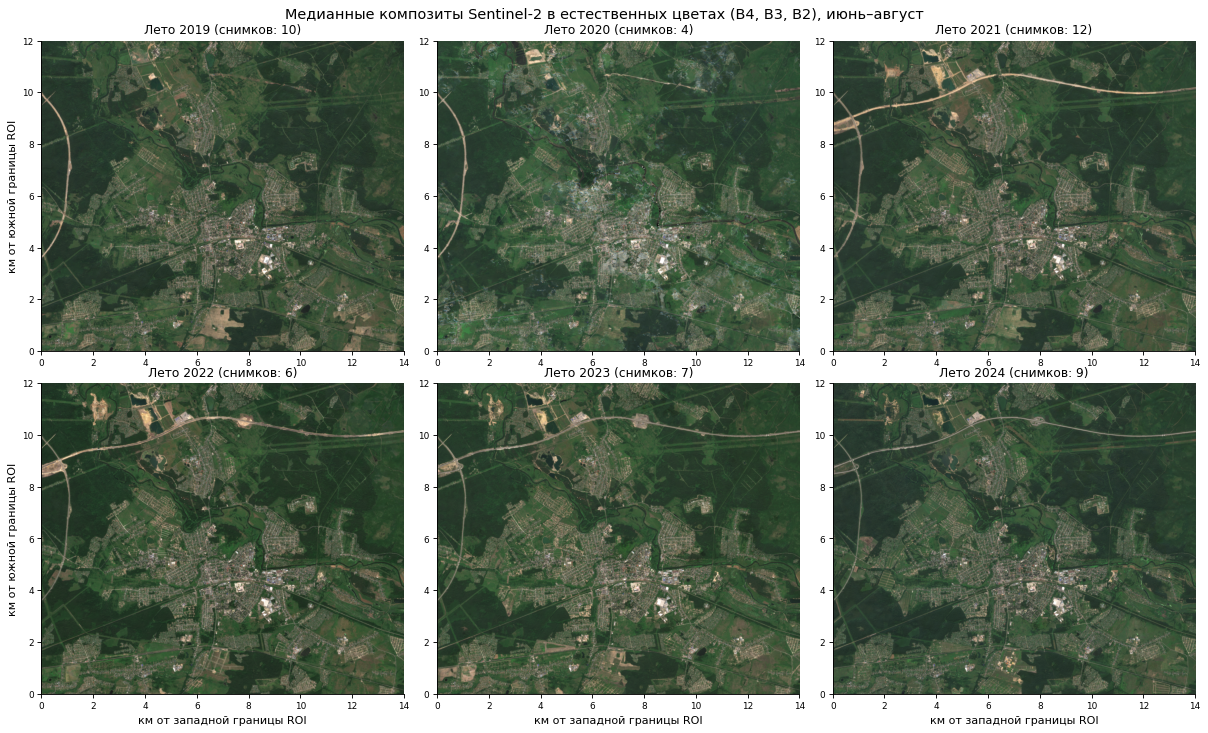

In [9]:
def read_s2(path):
    """Читает композит Sentinel-2: словарь {канал: массив float32}, пиксели без данных → NaN."""
    with rasterio.open(path) as src:
        data = src.read(masked=True).astype('float32').filled(np.nan)
        return {name: data[i] for i, name in enumerate(src.descriptions)}


s2 = {year: read_s2(s2_files[year]) for year in YEARS}

with rasterio.open(s2_files[YEARS[-1]]) as src:
    REF_PROFILE = src.profile.copy()            # шаблон метаданных для сохранения результатов
    RASTER_SHAPE = (src.height, src.width)
    PIXEL_AREA_M2 = abs(src.res[0] * src.res[1])
    print(f"Система координат: {src.crs}")
    print(f"Размер пикселя: {src.res[0]:g} × {src.res[1]:g} м, площадь пикселя {PIXEL_AREA_M2:g} м²")
    print(f"Размер растра: {src.width} × {src.height} пикселей, каналы: {', '.join(src.descriptions)}")
    print(f"Тип данных: {src.dtypes[0]}, NoData: {src.nodata}")

# Среднее отражение по каналам и число пикселей без безоблачных наблюдений
band_stats = pd.DataFrame({
    year: {**{f'{b}, сред.': np.nanmean(s2[year][b]) for b in S2_BANDS},
           'Пикселей без данных': int(np.isnan(s2[year]['B4']).sum())}
    for year in YEARS}).T
band_stats['Пикселей без данных'] = band_stats['Пикселей без данных'].astype(int)
display(band_stats.round(4))


def to_rgb(bands, vmax=0.3, gamma=1.4):
    """Синтез в естественных цветах (B4, B3, B2): растяжение отражения 0–vmax на яркость 0–1."""
    rgb = np.dstack([bands['B4'], bands['B3'], bands['B2']])
    return np.clip(np.nan_to_num(rgb) / vmax, 0, 1) ** (1 / gamma)


fig, axes = plt.subplots(2, 3, figsize=(15, 9), constrained_layout=True)
for ax, year in zip(axes.flat, YEARS):
    ax.imshow(to_rgb(s2[year]), extent=EXTENT_KM)
    ax.set_title(f'Лето {year} (снимков: {s2_info.loc[year, "Снимков"]})')
    ax.tick_params(labelsize=8)
for ax in axes[-1]:
    ax.set_xlabel('км от западной границы ROI')
for ax in axes[:, 0]:
    ax.set_ylabel('км от южной границы ROI')
fig.suptitle('Медианные композиты Sentinel-2 в естественных цветах (B4, B3, B2), июнь–август', fontsize=13)
plt.show()

Карты Dynamic World: 1400 × 1200 пикселей, тип int16, NoData = -32768
  2019: классы [0, 1, 2, 3, 4, 5, 6, 7, 8], пикселей без данных: 0
  2020: классы [0, 1, 2, 3, 4, 5, 6, 7, 8], пикселей без данных: 0
  2021: классы [0, 1, 2, 3, 4, 5, 6, 7], пикселей без данных: 0
  2022: классы [0, 1, 2, 3, 4, 5, 6, 7], пикселей без данных: 0
  2023: классы [0, 1, 2, 3, 4, 5, 6, 7], пикселей без данных: 0
  2024: классы [0, 1, 2, 3, 4, 5, 6, 7], пикселей без данных: 0


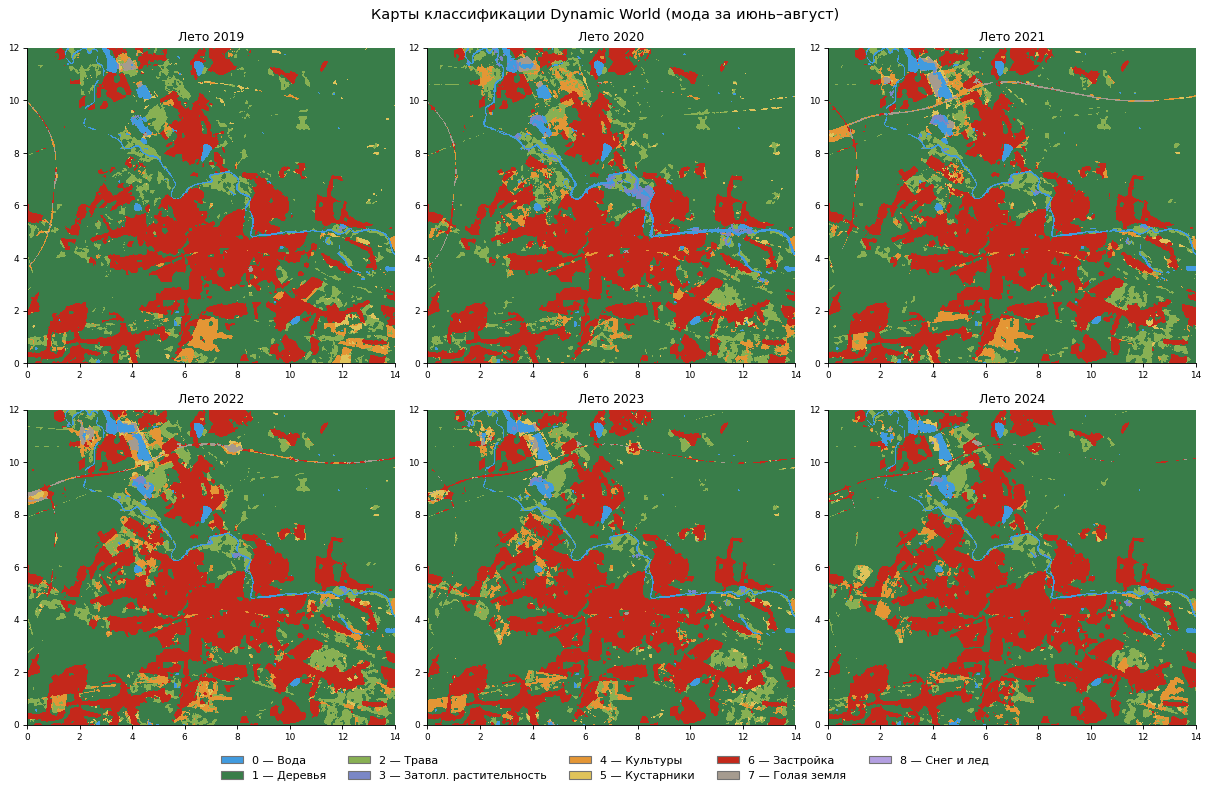

In [10]:
def read_classes(path):
    """Читает одноканальную карту классов и значение NoData."""
    with rasterio.open(path) as src:
        return src.read(1), int(src.nodata)


dw = {}
for year in YEARS:
    dw[year], DW_NODATA = read_classes(dw_files[year])

DW_COLORS = ['#' + c for c in DW_PALETTE]


def plot_class_maps(maps, colors, names, nodata, title, ncols=3, label_numbers=True):
    """Тематические карты классов (по одной на год) с общей легендой."""
    cmap = ListedColormap(colors)
    cmap.set_bad('black')                                   # пиксели без данных
    norm = BoundaryNorm(np.arange(-0.5, len(colors)), len(colors))
    nrows = int(np.ceil(len(maps) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4.5 * nrows + 0.8),
                             constrained_layout=True, squeeze=False)
    for ax, (key, arr) in zip(axes.flat, maps.items()):
        ax.imshow(np.ma.masked_equal(arr, nodata), cmap=cmap, norm=norm,
                  extent=EXTENT_KM, interpolation='nearest')
        ax.set_title(f'Лето {key}' if isinstance(key, (int, np.integer)) else str(key))
        ax.tick_params(labelsize=8)
    for ax in list(axes.flat)[len(maps):]:
        ax.axis('off')
    handles = [Patch(facecolor=c, edgecolor='0.45',
                     label=f'{i} — {n}' if label_numbers else n)
               for i, (c, n) in enumerate(zip(colors, names))]
    fig.legend(handles=handles, loc='outside lower center', ncol=min(len(names), 5), frameon=False)
    fig.suptitle(title, fontsize=13)
    plt.show()


print(f"Карты Dynamic World: {dw[YEARS[0]].shape[1]} × {dw[YEARS[0]].shape[0]} пикселей, "
      f"тип {dw[YEARS[0]].dtype}, NoData = {DW_NODATA}")
for year in YEARS:
    present = np.unique(dw[year][dw[year] != DW_NODATA])
    print(f"  {year}: классы {present.tolist()}, пикселей без данных: {(dw[year] == DW_NODATA).sum()}")

plot_class_maps(dw, DW_COLORS, DW_CLASS_NAMES, DW_NODATA,
                'Карты классификации Dynamic World (мода за июнь–август)')

### **4.2. Рассчитать все 8 индексов для каждого года (2019-2024)**


> **Примечание.** В качестве примера рассчета индексов можно использовать код из лекционных материалов, доступный по ссылке: https://u.to/4qBeIg





**Спектральные индексы** — это математические комбинации значений отражения в разных спектральных каналах, позволяющие выделить определенные типы объектов.








#### **Таблица 1. Основные спектральные индексы для анализа земного покрова**




| **Индекс** | **Формула** | **Назначение** | **Каналы Sentinel-2** |
|------------|-------------|----------------|------------------------|
| **NDVI** (Normalized Difference Vegetation Index) | (NIR - RED) / (NIR + RED) | Оценка состояния растительности | (B8 - B4) / (B8 + B4) |
| **NDWI** (Normalized Difference Water Index) | (GREEN - NIR) / (GREEN + NIR) | Выделение водных объектов | (B3 - B8) / (B3 + B8) |
| **NDBI** (Normalized Difference Built-up Index) | (SWIR - NIR) / (SWIR + NIR) | Выделение застроенных территорий | (B11 - B8) / (B11 + B8) |
| **SAVI** (Soil Adjusted Vegetation Index) | ((NIR - RED) / (NIR + RED + L)) * (1 + L), L=0.5 | Растительность с учетом почвы | ((B8 - B4) / (B8 + B4 + 0.5)) * 1.5 |
| **EVI** (Enhanced Vegetation Index) | 2.5 * ((NIR - RED) / (NIR + 6*RED - 7.5*BLUE + 1)) | Улучшенный вегетационный индекс | 2.5 * ((B8 - B4) / (B8 + 6*B4 - 7.5*B2 + 1)) |
| **MNDWI** (Modified NDWI) | (GREEN - SWIR) / (GREEN + SWIR) | Модифицированный водный индекс | (B3 - B11) / (B3 + B11) |
| **BSI** (Bare Soil Index) | ((SWIR + RED) - (NIR + BLUE)) / ((SWIR + RED) + (NIR + BLUE)) | Открытая почва | ((B11 + B4) - (B8 + B2)) / ((B11 + B4) + (B8 + B2)) |
| **NDSI** (Normalized Difference Snow Index) | (GREEN - SWIR) / (GREEN + SWIR) | Снежный покров | (B3 - B11) / (B3 + B11) |

NDSI и MNDWI вычисляются по одной формуле, поэтому высокие значения дают и снег, и вода. Снег отличается от воды высоким отражением в ближнем ИК-канале (B8 > 0.11), а вода ИК-излучение поглощает.


#### **Таблица 2. Интерпретация значений NDVI**



| **Диапазон NDVI** | **Тип покрова** | **Характеристика** |
|-------------------|-----------------|---------------------|
| < 0.0 | Вода | Водные поверхности, снег |
| 0.0 - 0.1 | Открытая почва | Песок, камни, бетон |
| 0.1 - 0.2 | Разреженная растительность | Степи, пустыни |
| 0.2 - 0.4 | Умеренная растительность | Кустарники, луга |
| 0.4 - 0.6 | Плотная растительность | Лиственные леса |
| > 0.6 | Очень плотная растительность | Тропические леса, хвойные леса |

#### **Таблица 3. Интерпретация значений NDWI**



| **Диапазон NDWI** | **Тип объекта** | **Описание** |
|-------------------|-----------------|--------------|
| > 0.3 | Водные объекты | Реки, озера, пруды |
| 0.0 - 0.3 | Влажная почва/растительность | Болота, заливные луга |
| -0.3 - 0.0 | Сухая растительность | Обычная растительность |
| < -0.3 | Застройка/почва | Городская застройка, открытая почва |

#### **Таблица 4. Интерпретация значений NDBI**



| **Диапазон NDBI** | **Тип территории** | **Характеристика** |
|-------------------|-------------------|---------------------|
| > 0.0 | Застроенные территории | Города, промзоны |
| -0.1 - 0.0 | Смешанные территории | Пригороды, села |
| < -0.1 | Природные территории | Леса, поля, водоемы |

#### **Таблица 5. Интерпретация значений SAVI**



| **Диапазон SAVI** | **Тип покрова** | **Описание** |
|-------------------|-----------------|---------------|
| < 0.1 | Открытая почва/вода | Водные объекты, голая почва |
| 0.1 - 0.2 | Очень разреженная растительность | Пустыни, каменистые участки |
| 0.2 - 0.4 | Разреженная растительность | Степи, саванны |
| 0.4 - 0.6 | Умеренная растительность | Сельхозугодья, луга |
| > 0.6 | Плотная растительность | Леса, густые кустарники |

#### **Таблица 6. Интерпретация значений EVI**



| **Диапазон EVI** | **Состояние растительности** | **Характеристика** |
|------------------|------------------------------|---------------------|
| < 0.0 | Нет растительности | Вода, снег, облака |
| 0.0 - 0.2 | Минимальная растительность | Голая почва, урбанизированные территории |
| 0.2 - 0.3 | Низкая биомасса | Травянистая растительность |
| 0.3 - 0.5 | Средняя биомасса | Кустарники, молодые посевы |
| 0.5 - 0.8 | Высокая биомасса | Зрелые леса, интенсивное сельское хозяйство |
| > 0.8 | Очень высокая биомасса | Тропические леса |

#### **Таблица 7. Интерпретация значений MNDWI**



| **Диапазон MNDWI** | **Тип объекта** | **Характеристика** |
|--------------------|-----------------|---------------------|
| > 0.5 | Глубокая вода | Озера, моря, водохранилища |
| 0.2 - 0.5 | Мелкая вода | Реки, каналы, мелководья |
| 0.0 - 0.2 | Влажные территории | Болота, рисовые поля |
| < 0.0 | Суша | Растительность, почва, застройка |

#### **Таблица 8. Интерпретация значений BSI**



| **Диапазон BSI** | **Тип поверхности** | **Описание** |
|-------------------|-------------------|---------------|
| > 0.1 | Открытая почва | Пашни, карьеры, пустыни |
| 0.0 - 0.1 | Частично покрытая почва | Разреженная растительность |
| -0.1 - 0.0 | Смешанный покров | Переходные зоны |
| < -0.1 | Растительность/вода | Леса, водоемы, плотная растительность |

#### **Таблица 9. Интерпретация значений NDSI**



| **Диапазон NDSI** | **Тип покрова** | **Характеристика** |
|-------------------|-----------------|---------------------|
| > 0.4 | Снежный покров | Чистый снег, ледники |
| 0.2 - 0.4 | Частичный снежный покров | Смешанный снег с растительностью |
| 0.0 - 0.2 | Возможный снег/лед | Тающий снег, иней, облака |
| -0.2 - 0.0 | Переходная зона | Влажная почва, туман |
| < -0.2 | Бесснежные территории | Растительность, почва, вода |

In [11]:
INDEX_NAMES = ['NDVI', 'NDWI', 'NDBI', 'SAVI', 'EVI', 'MNDWI', 'BSI', 'NDSI']


def normalized_difference(a, b):
    """Нормализованная разность (a - b) / (a + b)."""
    return (a - b) / (a + b)


def calc_indices(bands):
    """
    Рассчитывает 8 спектральных индексов по таблице 1.
    Отражение должно быть в диапазоне 0–1 (это важно для SAVI и EVI, где в знаменателе есть константы).
    """
    B2, B3, B4, B8, B11 = (bands[b] for b in ('B2', 'B3', 'B4', 'B8', 'B11'))
    with np.errstate(divide='ignore', invalid='ignore'):
        indices = {
            'NDVI':  normalized_difference(B8, B4),
            'NDWI':  normalized_difference(B3, B8),
            'NDBI':  normalized_difference(B11, B8),
            'SAVI':  (B8 - B4) / (B8 + B4 + 0.5) * 1.5,
            'EVI':   2.5 * (B8 - B4) / (B8 + 6 * B4 - 7.5 * B2 + 1),
            'MNDWI': normalized_difference(B3, B11),
            'BSI':   ((B11 + B4) - (B8 + B2)) / ((B11 + B4) + (B8 + B2)),
            'NDSI':  normalized_difference(B3, B11),
        }
    # деление на ноль дает ±inf — такие пиксели считаем пикселями без данных
    return {name: np.where(np.isfinite(arr), arr, np.nan).astype('float32') for name, arr in indices.items()}


indices = {year: calc_indices(s2[year]) for year in YEARS}

print("NDSI и MNDWI рассчитываются по одной формуле (B3 - B11) / (B3 + B11): совпадают —",
      np.array_equal(indices[2024]['NDSI'], indices[2024]['MNDWI'], equal_nan=True))

# Средние значения индексов по ROI для каждого года
index_means = pd.DataFrame({year: {name: np.nanmean(arr) for name, arr in indices[year].items()}
                            for year in YEARS})
print("\nСредние значения индексов по ROI:")
display(index_means.round(3))

# Описательная статистика индексов за 2024 год
index_stats_2024 = pd.DataFrame({
    name: {'мин': np.nanmin(arr), 'P5': np.nanpercentile(arr, 5), 'медиана': np.nanmedian(arr),
           'P95': np.nanpercentile(arr, 95), 'макс': np.nanmax(arr)}
    for name, arr in indices[2024].items()}).T
print("Распределение значений индексов, 2024 год:")
display(index_stats_2024.round(3))

NDSI и MNDWI рассчитываются по одной формуле (B3 - B11) / (B3 + B11): совпадают — True

Средние значения индексов по ROI:


,2019,2020,2021,2022,2023,2024
NDVI,0.724,0.716,0.712,0.735,0.715,0.718
NDWI,-0.650,-0.622,-0.636,-0.662,-0.638,-0.632
NDBI,-0.237,-0.253,-0.233,-0.274,-0.252,-0.235
SAVI,0.431,0.439,0.430,0.452,0.434,0.411
EVI,0.476,0.502,0.482,0.498,0.480,0.457
MNDWI,-0.501,-0.449,-0.489,-0.494,-0.475,-0.478
BSI,-0.200,-0.216,-0.199,-0.234,-0.212,-0.201
NDSI,-0.501,-0.449,-0.489,-0.494,-0.475,-0.478


Распределение значений индексов, 2024 год:


,мин,P5,медиана,P95,макс
NDVI,-0.505,0.336,0.788,0.866,1.000
NDWI,-0.992,-0.766,-0.677,-0.343,0.640
NDBI,-0.721,-0.399,-0.263,0.013,0.640
SAVI,-0.097,0.177,0.422,0.574,0.786
EVI,-10.212,0.193,0.464,0.664,3.459
MNDWI,-0.996,-0.595,-0.500,-0.305,0.778
BSI,-0.611,-0.361,-0.231,0.040,0.522
NDSI,-0.996,-0.595,-0.500,-0.305,0.778


### **4.3. Визуализировать каждый индекс для 2024 года с соответствующей цветовой шкалой**



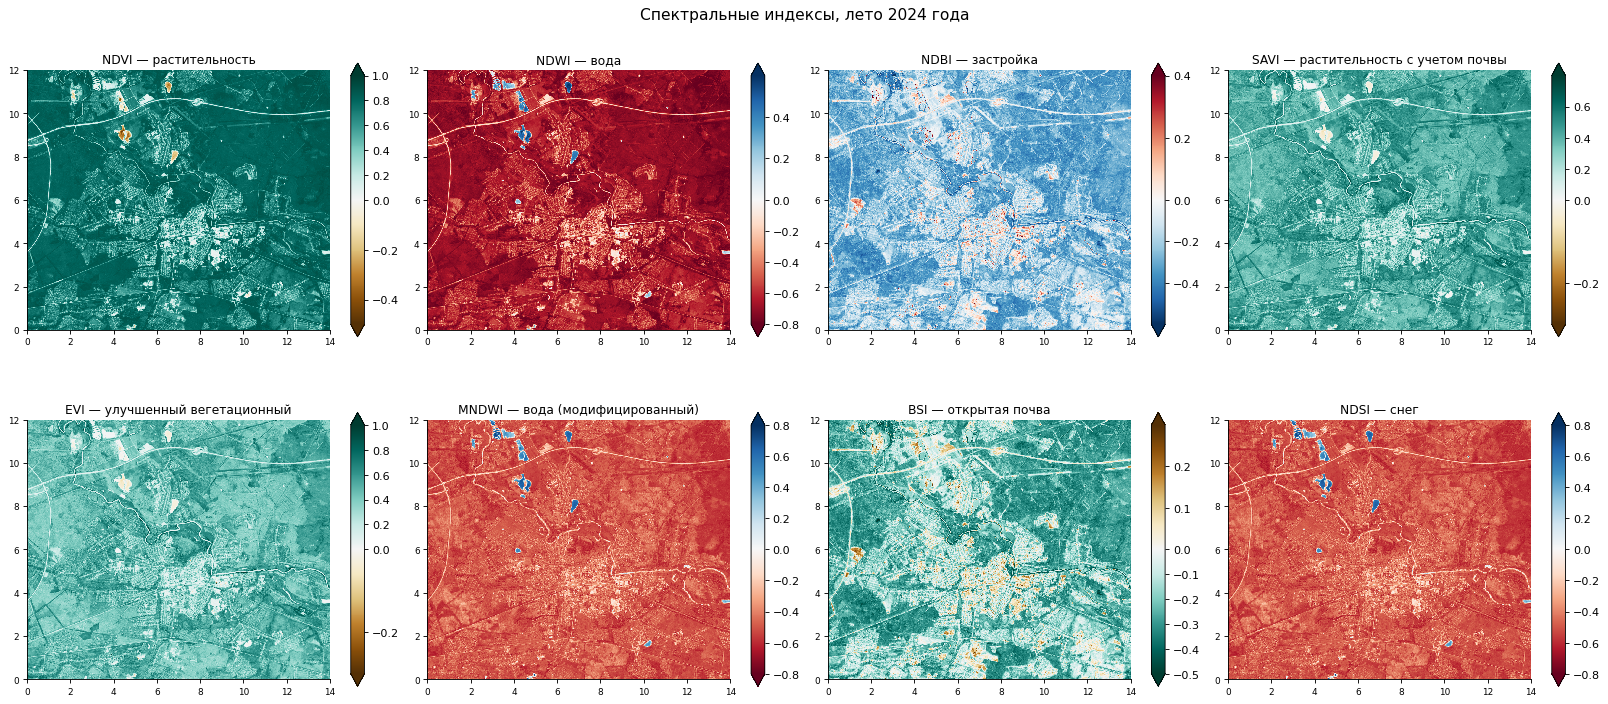

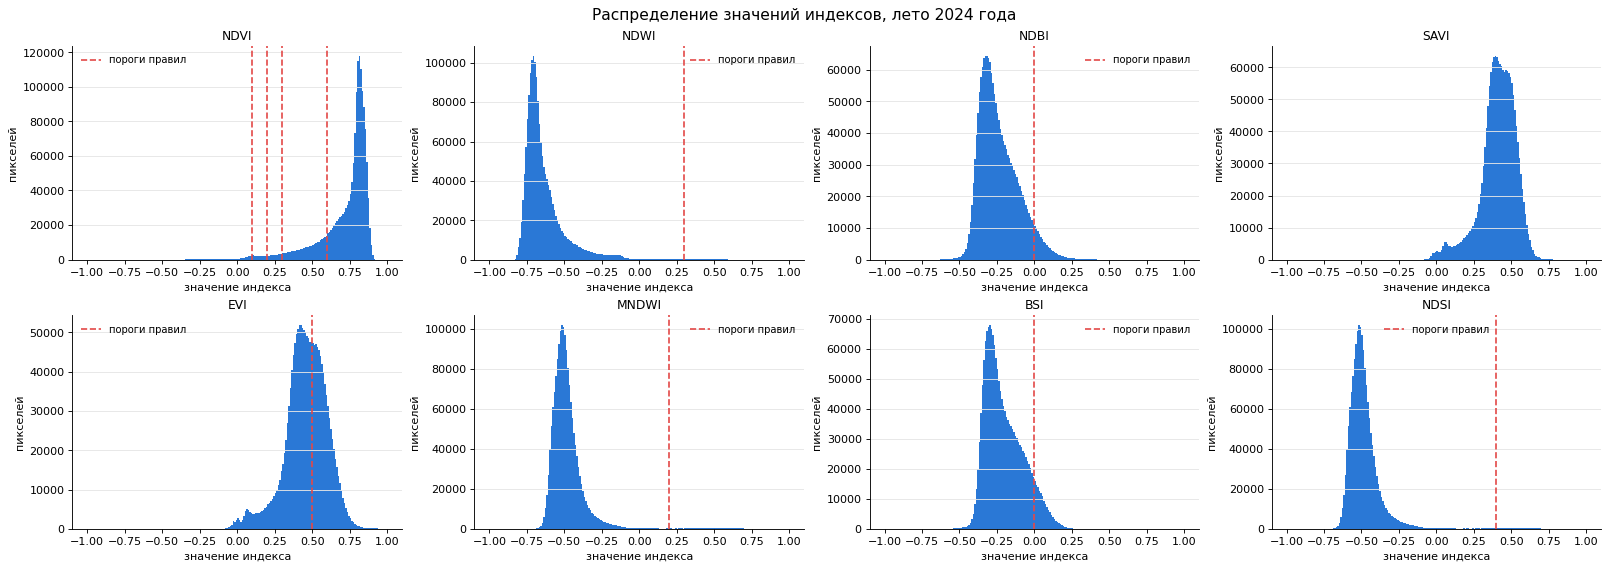

In [12]:
# Цветовые шкалы: расходящиеся, с нейтральной серединой в нуле.
# Вегетационные индексы: коричневый (нет растительности) → зеленый (растительность);
# водные индексы: красный (суша) → синий (вода); NDBI: синий → красный (застройка);
# BSI: зеленый → коричневый (открытая почва).
INDEX_VIS = {   # индекс: (шкала, мин, центр, макс)
    'NDVI':  ('BrBG',   -0.5, 0.0, 1.0),
    'NDWI':  ('RdBu',   -0.8, 0.0, 0.6),
    'NDBI':  ('RdBu_r', -0.6, 0.0, 0.4),
    'SAVI':  ('BrBG',   -0.3, 0.0, 0.8),
    'EVI':   ('BrBG',   -0.3, 0.0, 1.0),
    'MNDWI': ('RdBu',   -0.8, 0.0, 0.8),
    'BSI':   ('BrBG_r', -0.5, 0.0, 0.3),
    'NDSI':  ('RdBu',   -0.8, 0.0, 0.8),
}
INDEX_PURPOSE = {'NDVI': 'растительность', 'NDWI': 'вода', 'NDBI': 'застройка',
                 'SAVI': 'растительность с учетом почвы', 'EVI': 'улучшенный вегетационный',
                 'MNDWI': 'вода (модифицированный)', 'BSI': 'открытая почва', 'NDSI': 'снег'}
# Пороги, используемые в правилах сегментации (раздел 5.1)
INDEX_THRESHOLDS = {'NDVI': [0.1, 0.2, 0.3, 0.6], 'NDWI': [0.3], 'NDBI': [0.0], 'SAVI': [],
                    'EVI': [0.5], 'MNDWI': [0.2], 'BSI': [0.0], 'NDSI': [0.4]}

fig, axes = plt.subplots(2, 4, figsize=(20, 9), constrained_layout=True)
for ax, name in zip(axes.flat, INDEX_NAMES):
    cmap, vmin, vcenter, vmax = INDEX_VIS[name]
    im = ax.imshow(indices[2024][name], cmap=cmap, extent=EXTENT_KM, interpolation='nearest',
                   norm=TwoSlopeNorm(vmin=vmin, vcenter=vcenter, vmax=vmax))
    ax.set_title(f'{name} — {INDEX_PURPOSE[name]}')
    ax.tick_params(labelsize=8)
    fig.colorbar(im, ax=ax, shrink=0.8, extend='both')
fig.suptitle('Спектральные индексы, лето 2024 года', fontsize=14)
plt.show()

# Гистограммы индексов с порогами правил сегментации
fig, axes = plt.subplots(2, 4, figsize=(20, 7), constrained_layout=True)
for ax, name in zip(axes.flat, INDEX_NAMES):
    values = indices[2024][name]
    values = values[np.isfinite(values)]
    ax.hist(values, bins=200, range=(-1, 1), color='#2a78d6')
    for i, thr in enumerate(INDEX_THRESHOLDS[name]):
        ax.axvline(thr, color='#e34948', ls='--', lw=1.5, label='пороги правил' if i == 0 else None)
    ax.set_title(name)
    ax.set_xlabel('значение индекса')
    ax.set_ylabel('пикселей')
    ax.grid(axis='y', color='0.9')
    if INDEX_THRESHOLDS[name]:
        ax.legend(frameon=False, fontsize=9)
fig.suptitle('Распределение значений индексов, лето 2024 года', fontsize=14)
plt.show()

### **4.4. Сохранить все рассчитанные индексы в отдельные GeoTIFF файлы с сохранением геопривязки (сохранить в соответствующие папки по годам)**



In [13]:
def save_geotiff(path, array, profile, dtype, nodata, description=None, colormap=None):
    """
    Сохраняет одноканальный массив в GeoTIFF с геопривязкой из profile
    (СК и аффинное преобразование берутся из исходного композита).
    """
    prof = profile.copy()
    prof.pop('predictor', None)
    prof.update(driver='GTiff', count=1, dtype=dtype, nodata=nodata,
                compress='deflate', tiled=True, blockxsize=256, blockysize=256)
    if np.dtype(dtype).kind == 'f':
        prof['predictor'] = 3          # предиктор для чисел с плавающей точкой — лучше сжатие
    with rasterio.open(path, 'w', **prof) as dst:
        dst.write(array.astype(dtype), 1)
        if description:
            dst.set_band_description(1, description)
        if colormap:
            dst.write_colormap(1, colormap)
    return path


index_files = {}
rows = []
for year in YEARS:
    year_dir = os.path.join(INDEX_DIR, str(year))
    os.makedirs(year_dir, exist_ok=True)
    for name in INDEX_NAMES:
        path = os.path.join(year_dir, f'{name}_{year}.tif')
        index_files[(year, name)] = save_geotiff(path, indices[year][name], REF_PROFILE,
                                                 'float32', np.nan, description=name)
    files = [index_files[(year, n)] for n in INDEX_NAMES]
    rows.append({'Год': year, 'Папка': year_dir, 'Файлов': len(files),
                 'Размер, МБ': round(sum(os.path.getsize(f) for f in files) / 2**20, 1)})
display(pd.DataFrame(rows).set_index('Год'))

# Проверка: файл открывается с той же геопривязкой, значения совпадают с рассчитанными
with rasterio.open(index_files[(2024, 'NDVI')]) as src:
    print(f"{index_files[(2024, 'NDVI')]}: {src.crs}, пиксель {src.res[0]:g} м, "
          f"{src.width}×{src.height}, NoData={src.nodata}, канал «{src.descriptions[0]}»")
    print("Геопривязка совпадает с композитом:", src.transform == REF_PROFILE['transform'])
    print("Значения совпадают с рассчитанными:",
          np.array_equal(src.read(1), indices[2024]['NDVI'], equal_nan=True))

,Папка,Файлов,"Размер, МБ"
Год,,,
2019,indices\2019,8,40.0
2020,indices\2020,8,39.9
2021,indices\2021,8,39.9
2022,indices\2022,8,39.9
2023,indices\2023,8,40.2
2024,indices\2024,8,40.1


indices\2024\NDVI_2024.tif: EPSG:32637, пиксель 10 м, 1400×1200, NoData=nan, канал «NDVI»
Геопривязка совпадает с композитом: True
Значения совпадают с рассчитанными: True


## **5. Сегментация и классификация**

**Сегментация** — процесс разделения изображения на однородные регионы (сегменты) на основе заданных критериев .


### **5.1. Многопороговая сегментация с использованием спектральных индексов**



**Задание:** Реализовать классификацию земного покрова путем замены значений пикселей в растрах индексов на метки классов согласно пороговым правилам.

**Пояснение:** По сути необходимо преобразовать непрерывные значения индексов в дискретные классы (метки) на основе пороговых значений из Таблиц 2-9. Каждому пикселю присваивается числовая метка класса (0-7) в зависимости от значений спектральных индексов.






**Алгоритм многопороговой сегментации:**
1. Создать пустой растр для меток классов (заполнить значением -1 или 255 для "неклассифицировано")
2. Последовательно применить правила классификации
3. Каждое правило проверяется только для еще не классифицированных пикселей
4. Присвоить соответствующую метку класса пикселям, удовлетворяющим условию

**Иерархия правил классификации (применять строго последовательно):**
1. **Снег/лед (метка=1)**: (NDSI > 0.4) И (B8 > 0.11)
2. **Вода (метка=0)**: ((NDWI > 0.3) ИЛИ (MNDWI > 0.2)) И (еще не классифицировано)
3. **Застройка (метка=2)**: (NDBI > 0.0) И (NDVI < 0.2) И (еще не классифицировано)
4. **Густая растительность (метка=3)**: ((NDVI > 0.6) ИЛИ (EVI > 0.5)) И (еще не классифицировано)
5. **Умеренная растительность (метка=4)**: (0.3 ≤ NDVI ≤ 0.6) И (еще не классифицировано)
6. **Разреженная растительность (метка=5)**: (0.1 ≤ NDVI < 0.3) И (еще не классифицировано)
7. **Открытая почва (метка=6)**: (BSI > 0.0) И (NDVI < 0.1) И (еще не классифицировано)
8. **Прочее (метка=7)**: все оставшиеся неклассифицированные пиксели

**Обратите внимание:** открытая почва и пашня, как и застройка, дают NDBI > 0, поэтому правило 3 относит часть открытой почвы к застройке. Учитывайте это при интерпретации результатов и сравнении с Dynamic World.


**(МОЖЕТЕ СФОРМУЛИРОВАТЬ СВОИ ПРАВИЛА, ОСНОВЫВАЯСЬ НА ТАБЛИЦАХ, ПРИВЕДЕННЫХ ВЫШЕ!)**

In [14]:
SEG_CLASS_NAMES = ['Вода', 'Снег/лед', 'Застройка', 'Густая растительность',
                   'Умеренная растительность', 'Разреженная растительность', 'Открытая почва', 'Прочее']
SEG_COLORS = ['#419bdf', '#ffffff', '#c4281b', '#397d49', '#88b053', '#c6e48b', '#a59b8f', '#808080']
SEG_NODATA = 255     # «не классифицировано»; после применения всех правил так остаются только пиксели без данных

# Иерархия правил (метка, текст правила, условие); правила применяются строго по порядку,
# и каждое проверяется только для еще не классифицированных пикселей
SEG_RULES = [
    (1, '(NDSI > 0.4) И (B8 > 0.11)',      lambda ix, b8: (ix['NDSI'] > 0.4) & (b8 > 0.11)),
    (0, '(NDWI > 0.3) ИЛИ (MNDWI > 0.2)',  lambda ix, b8: (ix['NDWI'] > 0.3) | (ix['MNDWI'] > 0.2)),
    (2, '(NDBI > 0.0) И (NDVI < 0.2)',     lambda ix, b8: (ix['NDBI'] > 0.0) & (ix['NDVI'] < 0.2)),
    (3, '(NDVI > 0.6) ИЛИ (EVI > 0.5)',    lambda ix, b8: (ix['NDVI'] > 0.6) | (ix['EVI'] > 0.5)),
    (4, '0.3 ≤ NDVI ≤ 0.6',                lambda ix, b8: (ix['NDVI'] >= 0.3) & (ix['NDVI'] <= 0.6)),
    (5, '0.1 ≤ NDVI < 0.3',                lambda ix, b8: (ix['NDVI'] >= 0.1) & (ix['NDVI'] < 0.3)),
    (6, '(BSI > 0.0) И (NDVI < 0.1)',      lambda ix, b8: (ix['BSI'] > 0.0) & (ix['NDVI'] < 0.1)),
]


def segment(ix, b8):
    """
    Многопороговая сегментация: заменяет значения индексов метками классов 0–7.

    Параметры:
        ix (dict): словарь индексов {имя: массив}
        b8 (np.ndarray): отражение в канале B8 (нужно для правила снега)

    Возвращает:
        labels (np.ndarray, uint8): метки классов, 255 — нет данных
        log (list): сколько пикселей отнесено к классу каждым правилом
    """
    valid = np.isfinite(b8)
    for arr in ix.values():
        valid &= np.isfinite(arr)

    labels = np.full(b8.shape, SEG_NODATA, dtype=np.uint8)   # 1. пустой растр «не классифицировано»
    log = []
    for label, text, rule in SEG_RULES:                        # 2. правила по порядку
        unclassified = valid & (labels == SEG_NODATA)          # 3. только еще не классифицированные
        selected = unclassified & rule(ix, b8)
        labels[selected] = label                               # 4. присваиваем метку
        log.append((label, text, int(selected.sum())))
    rest = valid & (labels == SEG_NODATA)                      # 8. все оставшиеся → «Прочее»
    labels[rest] = 7
    log.append((7, 'все оставшиеся пиксели', int(rest.sum())))
    return labels, log


seg_2024, seg_log = segment(indices[2024], s2[2024]['B8'])

n_valid = int((seg_2024 != SEG_NODATA).sum())
rules_table = pd.DataFrame(
    [(i + 1, SEG_CLASS_NAMES[label], label, text, count, count / n_valid * 100)
     for i, (label, text, count) in enumerate(seg_log)],
    columns=['Шаг', 'Класс', 'Метка', 'Правило', 'Пикселей', '%']).set_index('Шаг')
print("Сегментация композита 2024 года — сколько пикселей отнесло к классу каждое правило:")
display(rules_table.round(2))

Сегментация композита 2024 года — сколько пикселей отнесло к классу каждое правило:


,Класс,Метка,Правило,Пикселей,%
Шаг,,,,,
1,Снег/лед,1,(NDSI > 0.4) И (B8 > 0.11),1,0.00
2,Вода,0,(NDWI > 0.3) ИЛИ (MNDWI > 0.2),12245,0.73
3,Застройка,2,(NDBI > 0.0) И (NDVI < 0.2),26797,1.60
4,Густая растительность,3,(NDVI > 0.6) ИЛИ (EVI > 0.5),1387586,82.59
5,Умеренная растительность,4,0.3 ≤ NDVI ≤ 0.6,221816,13.20
6,Разреженная растительность,5,0.1 ≤ NDVI < 0.3,29771,1.77
7,Открытая почва,6,(BSI > 0.0) И (NDVI < 0.1),1177,0.07
8,Прочее,7,все оставшиеся пиксели,607,0.04



### **5.2. Подсчет количества пикселей каждого класса**



**Задание:** После замены значений индексов на метки классов, подсчитать количество пикселей для каждой метки класса.

**Пояснение:** Используйте функции numpy.unique() или аналогичные для подсчета количества пикселей с каждой меткой. Это позволит получить статистику распределения классов на изображении.

**Что нужно получить:**
- Массив уникальных меток классов (0-7)
- Количество пикселей для каждой метки
- Процентное соотношение классов от общего числа пикселей

In [15]:
def count_classes(labels, n_classes, nodata):
    """Количество пикселей каждого класса 0..n_classes-1 (пиксели без данных не учитываются)."""
    values, counts = np.unique(labels[labels != nodata], return_counts=True)
    result = np.zeros(n_classes, dtype=np.int64)
    result[values.astype(int)] = counts
    return values, result


values, counts_2024 = count_classes(seg_2024, len(SEG_CLASS_NAMES), SEG_NODATA)
print("Уникальные метки классов:", values)
print("Количество пикселей по меткам 0–7:", counts_2024)

class_stats_2024 = pd.DataFrame({
    'Метка': range(len(SEG_CLASS_NAMES)),
    'Класс': SEG_CLASS_NAMES,
    'Пикселей': counts_2024,
    '% от числа пикселей': counts_2024 / counts_2024.sum() * 100,
}).set_index('Метка')
display(class_stats_2024.round(2))
print(f"Всего классифицировано пикселей: {counts_2024.sum():,}".replace(',', ' '))

Уникальные метки классов: [0 1 2 3 4 5 6 7]
Количество пикселей по меткам 0–7: [  12245       1   26797 1387586  221816   29771    1177     607]


,Класс,Пикселей,% от числа пикселей
Метка,,,
0,Вода,12245,0.73
1,Снег/лед,1,0.00
2,Застройка,26797,1.60
3,Густая растительность,1387586,82.59
4,Умеренная растительность,221816,13.20
5,Разреженная растительность,29771,1.77
6,Открытая почва,1177,0.07
7,Прочее,607,0.04


Всего классифицировано пикселей: 1 680 000


### **5.3. Применение сегментации ко всем временным срезам**




**Задание:** Применить разработанный алгоритм сегментации ко всем медианным композитам (2019-2024).

**Пояснение:** Использовать одинаковые пороговые значения для всех лет для обеспечения сопоставимости результатов при анализе динамики. Сохранить результаты сегментации как растры с метками классов.

**Выходные данные:**
- 6 растров с метками классов (по одному на каждый год)
- Таблица с количеством пикселей каждого класса для каждого года
- Формат сохранения: GeoTIFF с сохранением геопривязки

In [16]:
def hex_to_rgba(color):
    color = color.lstrip('#')
    return tuple(int(color[i:i + 2], 16) for i in (0, 2, 4)) + (255,)


# Цветовая таблица встраивается в GeoTIFF — в ГИС файл сразу отображается в цветах классов
SEG_COLORMAP = {i: hex_to_rgba(c) for i, c in enumerate(SEG_COLORS)}

seg, seg_files = {}, {}
pixel_counts = {}
for year in YEARS:
    seg[year], _ = segment(indices[year], s2[year]['B8'])   # одинаковые пороги для всех лет
    seg_files[year] = save_geotiff(os.path.join(SEG_DIR, f'segmentation_{year}.tif'), seg[year],
                                   REF_PROFILE, 'uint8', SEG_NODATA,
                                   description='land cover class', colormap=SEG_COLORMAP)
    _, pixel_counts[year] = count_classes(seg[year], len(SEG_CLASS_NAMES), SEG_NODATA)

seg_pixel_counts = pd.DataFrame(pixel_counts, index=SEG_CLASS_NAMES)
seg_pixel_counts.index.name = 'Класс'
seg_pixel_counts.loc['Нет данных'] = [int((seg[y] == SEG_NODATA).sum()) for y in YEARS]

print("Сохранены растры с метками классов:", ', '.join(seg_files.values()))
print("\nКоличество пикселей каждого класса по годам:")
display(seg_pixel_counts)
seg_pixel_counts.to_csv(os.path.join(RESULTS_DIR, 'segmentation_pixel_counts.csv'), encoding='utf-8-sig')
seg_pixel_counts = seg_pixel_counts.drop('Нет данных')

Сохранены растры с метками классов: segmentation\segmentation_2019.tif, segmentation\segmentation_2020.tif, segmentation\segmentation_2021.tif, segmentation\segmentation_2022.tif, segmentation\segmentation_2023.tif, segmentation\segmentation_2024.tif

Количество пикселей каждого класса по годам:


,2019,2020,2021,2022,2023,2024
Класс,,,,,,
Вода,8482,7068,9822,10622,10904,12245
Снег/лед,2,16,2,6,5,1
Застройка,21970,23087,39378,40661,32038,26797
Густая растительность,1385409,1376510,1331989,1357744,1319956,1387586
Умеренная растительность,233834,240892,263280,234666,274374,221816
Разреженная растительность,29014,30765,34045,34378,40922,29771
Открытая почва,677,661,926,1244,1069,1177
Прочее,612,861,558,679,732,607
Нет данных,0,140,0,0,0,0


### **5.4. Визуализация результатов сегментации**






**Задание:** Создать тематические карты классификации с легендой.

**Пояснение:** Назначить каждой метке класса соответствующий цвет для визуализации. Использовать стандартную цветовую схему для классов земного покрова.

**Цветовая схема для визуализации:**
- 0 - Вода: синий (#419bdf)
- 1 - Снег/лед: белый (#ffffff)  
- 2 - Застройка: красный (#c4281b)
- 3 - Густая растительность: темно-зеленый (#397d49)
- 4 - Умеренная растительность: зеленый (#88b053)
- 5 - Разреженная растительность: светло-зеленый (#c6e48b)
- 6 - Открытая почва: коричневый (#a59b8f)
- 7 - Прочее: серый (#808080)

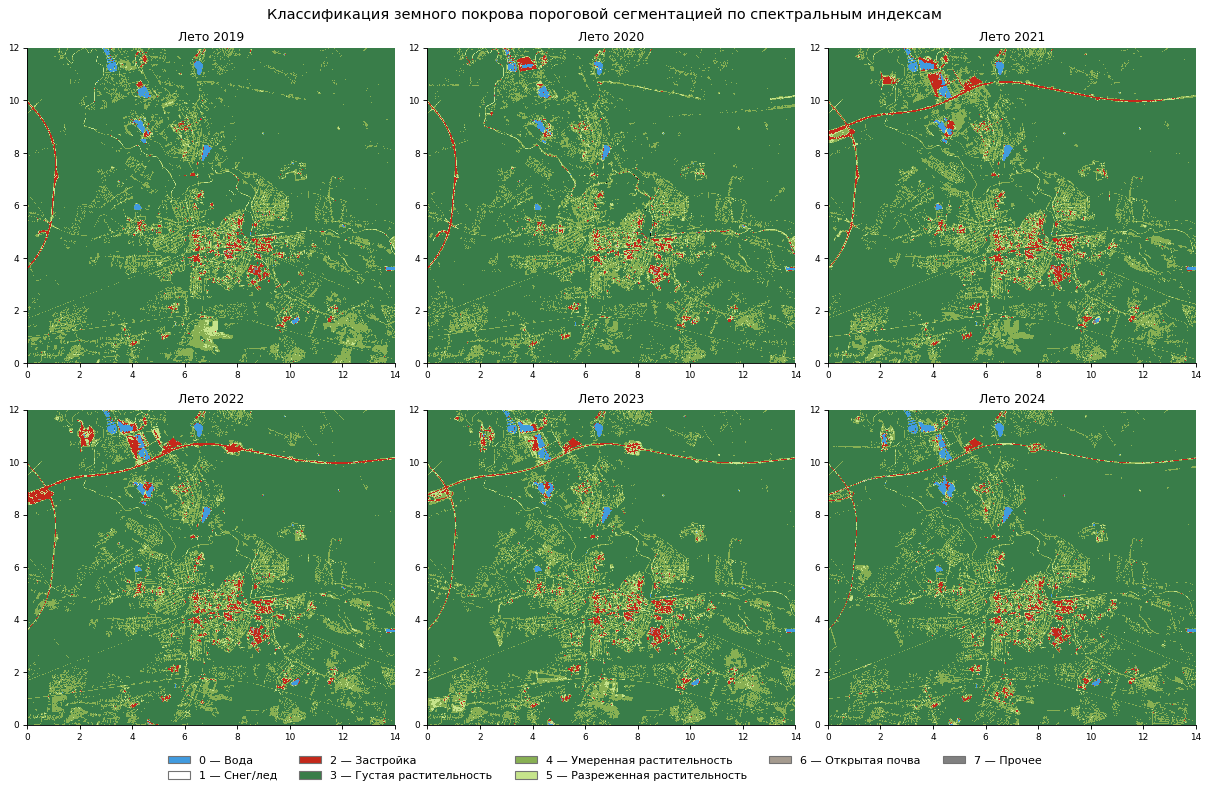

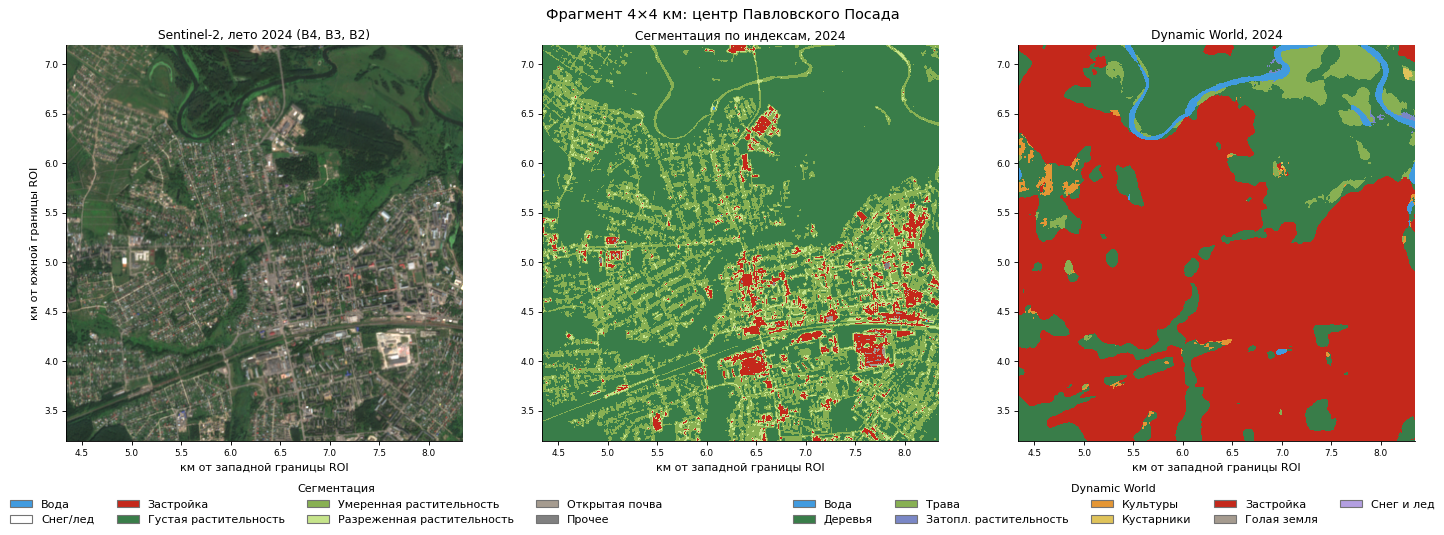

In [17]:
plot_class_maps(seg, SEG_COLORS, SEG_CLASS_NAMES, SEG_NODATA,
                'Классификация земного покрова пороговой сегментацией по спектральным индексам')

# Фрагмент 4×4 км вокруг центра города: композит, сегментация и Dynamic World за 2024 год
HALF = 200                                    # пикселей (2 км) в каждую сторону от центра
town_col = int(TOWN_KM[0] * 1000 / SCALE)
town_row = int((ROI_HEIGHT_KM - TOWN_KM[1]) * 1000 / SCALE)
win = (slice(town_row - HALF, town_row + HALF), slice(town_col - HALF, town_col + HALF))
win_extent = [(town_col - HALF) * SCALE / 1000, (town_col + HALF) * SCALE / 1000,
              ROI_HEIGHT_KM - (town_row + HALF) * SCALE / 1000, ROI_HEIGHT_KM - (town_row - HALF) * SCALE / 1000]

fig, axes = plt.subplots(1, 3, figsize=(18, 6.6), constrained_layout=True)
axes[0].imshow(to_rgb(s2[2024])[win], extent=win_extent)
axes[0].set_title('Sentinel-2, лето 2024 (B4, B3, B2)')
axes[1].imshow(np.ma.masked_equal(seg[2024][win], SEG_NODATA), cmap=ListedColormap(SEG_COLORS),
               norm=BoundaryNorm(np.arange(-0.5, 8), 8), extent=win_extent, interpolation='nearest')
axes[1].set_title('Сегментация по индексам, 2024')
axes[2].imshow(np.ma.masked_equal(dw[2024][win], DW_NODATA), cmap=ListedColormap(DW_COLORS),
               norm=BoundaryNorm(np.arange(-0.5, 9), 9), extent=win_extent, interpolation='nearest')
axes[2].set_title('Dynamic World, 2024')
for ax in axes:
    ax.set_xlabel('км от западной границы ROI')
    ax.tick_params(labelsize=8)
axes[0].set_ylabel('км от южной границы ROI')
fig.legend(handles=[Patch(facecolor=c, edgecolor='0.45', label=n) for c, n in zip(SEG_COLORS, SEG_CLASS_NAMES)],
           loc='outside lower left', ncol=4, frameon=False, title='Сегментация')
fig.legend(handles=[Patch(facecolor=c, edgecolor='0.45', label=n) for c, n in zip(DW_COLORS, DW_CLASS_NAMES)],
           loc='outside lower right', ncol=5, frameon=False, title='Dynamic World')
fig.suptitle('Фрагмент 4×4 км: центр Павловского Посада', fontsize=13)
plt.show()

## **6. Анализ динамики изменений на сегментированных растрах**

### **6.1. Рассчитать площади всех классов для каждого года**



**Формула перевода пикселей в площадь:**
```
Площадь (га) = Количество_пикселей × (Разрешение_м)² / 10000
Площадь (км²) = Количество_пикселей × (Разрешение_м)² / 1000000
```
Для Sentinel-2: разрешение = 10 м, следовательно:
- 1 пиксель = 100 м² = 0.01 га
- 100 пикселей = 1 га
- 10000 пикселей = 1 км²

Формула верна для растров в метрической проекции (UTM), где размер пикселя задан в метрах; размер пикселя берите из растра (`src.res`).

In [18]:
# Размер пикселя берется из растра (в метрической проекции UTM он задан в метрах)
with rasterio.open(seg_files[2024]) as src:
    res_x, res_y = src.res
PIXEL_AREA_M2 = res_x * res_y
PIXEL_HA = PIXEL_AREA_M2 / 10_000          # 1 пиксель 10×10 м = 0.01 га
ROI_PIXELS = RASTER_SHAPE[0] * RASTER_SHAPE[1]
ROI_HA = ROI_PIXELS * PIXEL_HA
print(f"Пиксель {res_x:g}×{res_y:g} м = {PIXEL_AREA_M2:g} м² = {PIXEL_HA:g} га; "
      f"ROI: {ROI_PIXELS:,} пикселей = {ROI_HA:,.0f} га = {ROI_HA / 100:,.0f} км²".replace(',', ' '))


def area_tables(pixel_counts):
    """Площади классов по годам: га, км² и доля от площади ROI (%)."""
    return {
        'ha': pixel_counts * PIXEL_AREA_M2 / 10_000,
        'km2': pixel_counts * PIXEL_AREA_M2 / 1_000_000,
        'pct': pixel_counts / ROI_PIXELS * 100,
    }


seg_areas = area_tables(seg_pixel_counts)
seg_area_ha = seg_areas['ha']

print("\nПлощадь классов, га:")
display(seg_area_ha.round(1))
print("Площадь классов, км²:")
display(seg_areas['km2'].round(3))
print("Доля от площади ROI, %:")
display(seg_areas['pct'].round(2))

Пиксель 10×10 м = 100 м² = 0.01 га; ROI: 1 680 000 пикселей = 16 800 га = 168 км²

Площадь классов, га:


,2019,2020,2021,2022,2023,2024
Класс,,,,,,
Вода,84.8,70.7,98.2,106.2,109.0,122.4
Снег/лед,0.0,0.2,0.0,0.1,0.0,0.0
Застройка,219.7,230.9,393.8,406.6,320.4,268.0
Густая растительность,13854.1,13765.1,13319.9,13577.4,13199.6,13875.9
Умеренная растительность,2338.3,2408.9,2632.8,2346.7,2743.7,2218.2
Разреженная растительность,290.1,307.6,340.4,343.8,409.2,297.7
Открытая почва,6.8,6.6,9.3,12.4,10.7,11.8
Прочее,6.1,8.6,5.6,6.8,7.3,6.1


Площадь классов, км²:


,2019,2020,2021,2022,2023,2024
Класс,,,,,,
Вода,0.848,0.707,0.982,1.062,1.090,1.224
Снег/лед,0.000,0.002,0.000,0.001,0.000,0.000
Застройка,2.197,2.309,3.938,4.066,3.204,2.680
Густая растительность,138.541,137.651,133.199,135.774,131.996,138.759
Умеренная растительность,23.383,24.089,26.328,23.467,27.437,22.182
Разреженная растительность,2.901,3.076,3.404,3.438,4.092,2.977
Открытая почва,0.068,0.066,0.093,0.124,0.107,0.118
Прочее,0.061,0.086,0.056,0.068,0.073,0.061


Доля от площади ROI, %:


,2019,2020,2021,2022,2023,2024
Класс,,,,,,
Вода,0.50,0.42,0.58,0.63,0.65,0.73
Снег/лед,0.00,0.00,0.00,0.00,0.00,0.00
Застройка,1.31,1.37,2.34,2.42,1.91,1.60
Густая растительность,82.46,81.94,79.29,80.82,78.57,82.59
Умеренная растительность,13.92,14.34,15.67,13.97,16.33,13.20
Разреженная растительность,1.73,1.83,2.03,2.05,2.44,1.77
Открытая почва,0.04,0.04,0.06,0.07,0.06,0.07
Прочее,0.04,0.05,0.03,0.04,0.04,0.04


### **6.2. Построить графики динамики изменений для каждого класса**



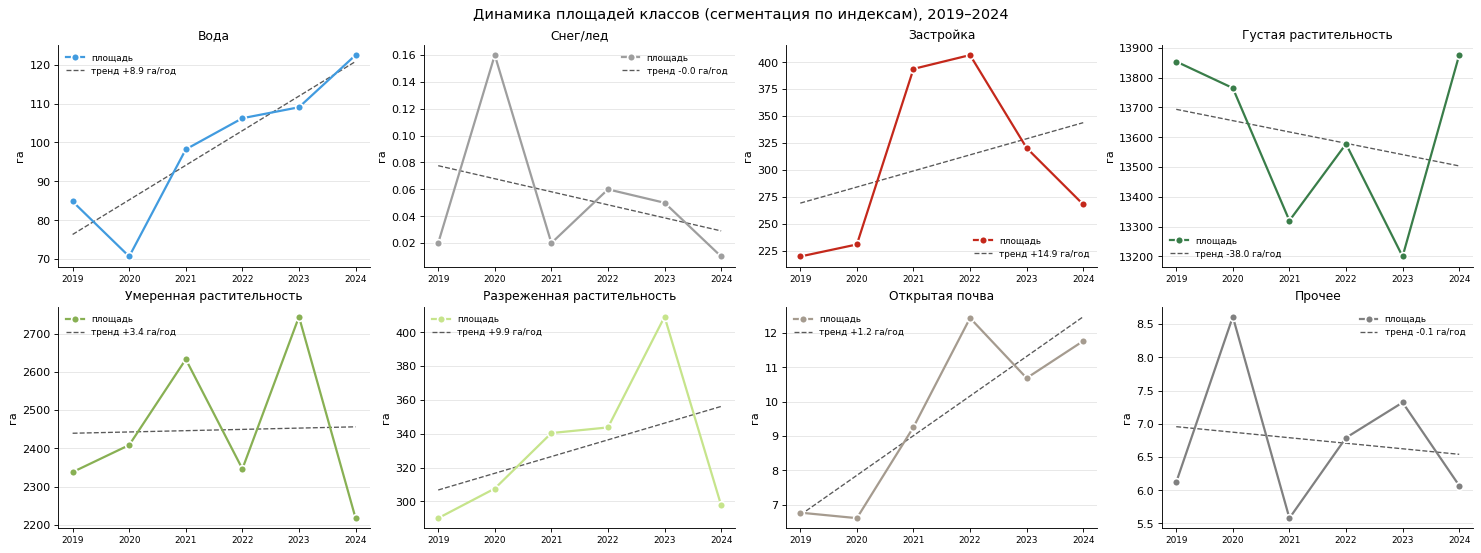

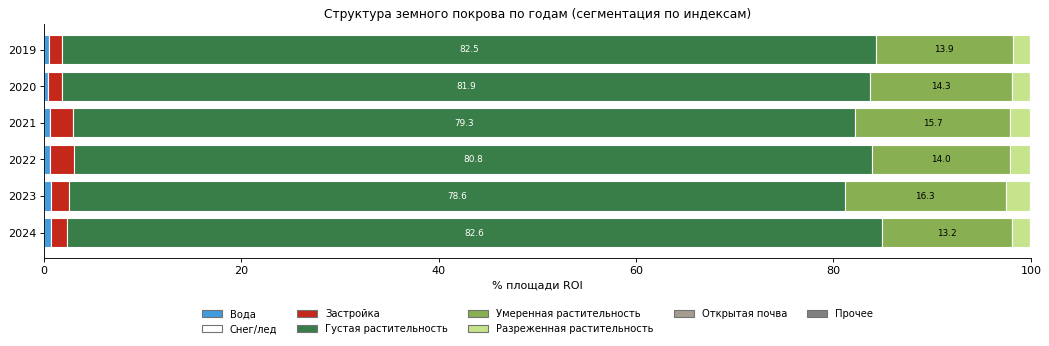

In [19]:
def plot_dynamics(area_ha, colors, title, ncols=4):
    """
    Малые множители: динамика площади каждого класса по годам с линейным трендом.
    Каждый класс на своем графике со своим масштабом оси Y — так видны изменения малых классов.
    """
    years = np.array(area_ha.columns, dtype=float)
    n = len(area_ha)
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.6 * ncols, 3.4 * nrows), constrained_layout=True)
    for ax, (name, row), color in zip(axes.flat, area_ha.iterrows(), colors):
        line_color = color if color.lower() not in ('#ffffff', '#fff') else '#9e9e9e'
        values = row.values.astype(float)
        ax.plot(years, values, color=line_color, lw=2, marker='o', ms=7,
                markeredgecolor='white', markeredgewidth=1.5, zorder=3, label='площадь')
        if np.ptp(values) > 0:
            slope, intercept = np.polyfit(years, values, 1)
            ax.plot(years, slope * years + intercept, color='0.35', lw=1.2, ls='--',
                    label=f'тренд {slope:+.1f} га/год')
            ax.legend(frameon=False, fontsize=8, loc='best')
        else:
            ax.text(0.5, 0.5, 'класс отсутствует' if values.max() == 0 else 'без изменений',
                    transform=ax.transAxes, ha='center', color='0.4')
        ax.set_title(name)
        ax.set_xticks(years)
        ax.set_xticklabels([str(int(y)) for y in years], fontsize=8)
        ax.set_ylabel('га')
        ax.grid(axis='y', color='0.9')
    for ax in list(axes.flat)[n:]:
        ax.axis('off')
    fig.suptitle(title, fontsize=13)
    plt.show()


def plot_structure(area_ha, colors, title):
    """Структура покрова по годам: доли классов (%) в 100-процентных столбцах."""
    shares = area_ha / area_ha.sum() * 100
    fig, ax = plt.subplots(figsize=(13, 4.2), constrained_layout=True)
    left = np.zeros(shares.shape[1])
    labels = [str(y) for y in shares.columns]
    for (name, row), color in zip(shares.iterrows(), colors):
        ax.barh(labels, row.values, left=left, color=color, edgecolor='white', linewidth=1, label=name)
        for i, (x0, w) in enumerate(zip(left, row.values)):
            if w >= 4:
                ax.text(x0 + w / 2, i, f'{w:.1f}', ha='center', va='center', fontsize=8,
                        color='white' if color.lower() in ('#397d49', '#c4281b', '#808080', '#419bdf') else 'black')
        left += row.values
    ax.set_xlim(0, 100)
    ax.set_xlabel('% площади ROI')
    ax.invert_yaxis()
    handles = [Patch(facecolor=c, edgecolor='0.45', label=n) for c, n in zip(colors, shares.index)]
    ax.legend(handles=handles, loc='upper center', bbox_to_anchor=(0.5, -0.18), ncol=5, frameon=False, fontsize=9)
    ax.set_title(title)
    plt.show()


plot_dynamics(seg_area_ha, SEG_COLORS, 'Динамика площадей классов (сегментация по индексам), 2019–2024')
plot_structure(seg_area_ha, SEG_COLORS, 'Структура земного покрова по годам (сегментация по индексам)')

### **6.3. Рассчитать все статистические показатели**



**Обязательные метрики для каждого класса:**

1. **Абсолютные показатели:**
   - Площадь в га и км² для каждого года
   - Количество пикселей
   - Процент от общей площади ROI

2. **Показатели изменений:**
   - Абсолютное изменение площади (га): ΔS = S₂₀₂₄ - S₂₀₁₉
   - Относительное изменение (%): (S₂₀₂₄ - S₂₀₁₉) / S₂₀₁₉ × 100%
   - Среднегодовой прирост (га/год): ΔS / количество_лет (2024 - 2019 = 5)
   - Среднегодовой темп роста (%/год): ((S₂₀₂₄/S₂₀₁₉)^(1/5) - 1) × 100%

3. **Статистика временного ряда:**
   - Коэффициент вариации: CV = σ/μ × 100% (вспомните материал прошлого семестра, а именно работу в numpy)
   - Стандартное отклонение площадей
   - Наклон линейного тренда площади (га/год) и коэффициент детерминации R² (`np.polyfit`)

In [20]:
def absolute_table(pixel_counts):
    """Абсолютные показатели: пиксели, га, км² и % ROI для каждого класса и года."""
    areas = area_tables(pixel_counts)
    parts = {'пикселей': pixel_counts.astype(int), 'га': areas['ha'].round(1),
             'км²': areas['km2'].round(3), '% ROI': areas['pct'].round(2)}
    index = pd.MultiIndex.from_product([pixel_counts.index, list(parts)], names=['Класс', 'Показатель'])
    rows = [parts[metric].loc[name].tolist() for name, metric in index]
    return pd.DataFrame(rows, index=index, columns=pixel_counts.columns, dtype=object)


def dynamics_stats(area_ha):
    """
    Показатели изменений и статистика временного ряда площадей (га) для каждого класса.
    σ — стандартное отклонение по всем 6 годам (np.std, ddof=0).
    """
    years = np.array(area_ha.columns, dtype=float)
    n_years = years[-1] - years[0]                       # 2024 - 2019 = 5 лет
    rows = {}
    for name, row in area_ha.iterrows():
        s = row.values.astype(float)
        s0, s1 = s[0], s[-1]
        ds = s1 - s0
        mean, std = s.mean(), s.std()
        if np.ptp(s) > 0:
            slope, intercept = np.polyfit(years, s, 1)
            fitted = slope * years + intercept
            r2 = 1 - ((s - fitted) ** 2).sum() / ((s - mean) ** 2).sum()
        else:
            slope, r2 = 0.0, np.nan
        rows[name] = {
            f'S_{int(years[0])}, га': s0,
            f'S_{int(years[-1])}, га': s1,
            'ΔS, га': ds,
            'Δ, %': ds / s0 * 100 if s0 > 0 else np.nan,
            'Прирост, га/год': ds / n_years,
            'Темп, %/год': ((s1 / s0) ** (1 / n_years) - 1) * 100 if s0 > 0 else np.nan,
            'Среднее, га': mean,
            'σ, га': std,
            'CV, %': std / mean * 100 if mean > 0 else np.nan,
            'Наклон тренда, га/год': slope,
            'R²': r2,
        }
    return pd.DataFrame(rows).T


print("1. Абсолютные показатели (сегментация по индексам):")
display(absolute_table(seg_pixel_counts))

seg_stats = dynamics_stats(seg_area_ha)
print("2–3. Показатели изменений и статистика временного ряда:")
display(seg_stats.round(2))

1. Абсолютные показатели (сегментация по индексам):


2019     2020     2021     2022     2023     2024
Класс                      Показатель                                                      
Вода                       пикселей       8482     7068     9822    10622    10904    12245
                           га             84.8     70.7     98.2    106.2    109.0    122.4
                           км²           0.848    0.707    0.982    1.062     1.09    1.224
                           % ROI           0.5     0.42     0.58     0.63     0.65     0.73
Снег/лед                   пикселей          2       16        2        6        5        1
                           га              0.0      0.2      0.0      0.1      0.0      0.0
                           км²             0.0    0.002      0.0    0.001      0.0      0.0
                           % ROI           0.0      0.0      0.0      0.0      0.0      0.0
Застройка                  пикселей      21970    23087    39378    40661    32038    26797
                           га            219.7    230.9    393.8    406.6    320.4    268.0
                           км²           2.197    2.309    3.938    4.066    3.204     2.68
                           % ROI          1.31     1.37     2.34     2.42     1.91      1.6
Густая растительность      пикселей    1385409  1376510  1331989  1357744  1319956  1387586
                           га          13854.1  13765.1  13319.9  13577.4  13199.6  13875.9
                           км²         138.541  137.651  133.199  135.774  131.996  138.759
                           % ROI         82.46    81.94    79.29    80.82    78.57    82.59
Умеренная растительность   пикселей     233834   240892   263280   234666   274374   221816
                           га           2338.3   2408.9   2632.8   2346.7   2743.7   2218.2
                           км²          23.383   24.089   26.328   23.467   27.437   22.182
                           % ROI         13.92    14.34    15.67    13.97    16.33     13.2
Разреженная растительность пикселей      29014    30765    34045    34378    40922    29771
                           га            290.1    307.6    340.4    343.8    409.2    297.7
                           км²           2.901    3.076    3.404    3.438    4.092    2.977
                           % ROI          1.73     1.83     2.03     2.05     2.44     1.77
Открытая почва             пикселей        677      661      926     1244     1069     1177
                           га              6.8      6.6      9.3     12.4     10.7     11.8
                           км²           0.068    0.066    0.093    0.124    0.107    0.118
                           % ROI          0.04     0.04     0.06     0.07     0.06     0.07
Прочее                     пикселей        612      861      558      679      732      607
                           га              6.1      8.6      5.6      6.8      7.3      6.1
                           км²           0.061    0.086    0.056    0.068    0.073    0.061
                           % ROI          0.04     0.05     0.03     0.04     0.04     0.04

2–3. Показатели изменений и статистика временного ряда:


,"S_2019, га","S_2024, га","ΔS, га","Δ, %","Прирост, га/год","Темп, %/год","Среднее, га","σ, га","CV, %","Наклон тренда, га/год",R²
Вода,84.82,122.45,37.63,44.36,7.53,7.62,98.57,16.86,17.10,8.89,0.81
Снег/лед,0.02,0.01,-0.01,-50.00,-0.00,-12.94,0.05,0.05,95.40,-0.01,0.11
Застройка,219.70,267.97,48.27,21.97,9.65,4.05,306.55,73.68,24.03,14.93,0.12
Густая растительность,13854.09,13875.86,21.77,0.16,4.35,0.03,13598.66,260.52,1.92,-38.01,0.06
Умеренная растительность,2338.34,2218.16,-120.18,-5.14,-24.04,-1.05,2448.10,181.78,7.43,3.35,0.00
Разреженная растительность,290.14,297.71,7.57,2.61,1.51,0.52,331.49,40.19,12.12,9.88,0.18
Открытая почва,6.77,11.77,5.00,73.86,1.00,11.70,9.59,2.27,23.71,1.15,0.75
Прочее,6.12,6.07,-0.05,-0.82,-0.01,-0.16,6.75,1.00,14.84,-0.08,0.02


### **6.4. Определить какие классы показали наибольшие изменения**



**Критерии определения значимых изменений:**
- Изменение площади > 10% от начального значения
- Абсолютное изменение > 10 га
- Изменение направленное: R² линейного тренда ≥ 0.5 (иначе это межгодовые колебания)
- Ранжировать классы по величине относительных изменений

In [21]:
REL_THRESHOLD, ABS_THRESHOLD_HA, R2_THRESHOLD = 10, 10, 0.5


def significant_changes(stats):
    """
    Проверяет критерии значимого изменения и ранжирует классы по |Δ%|:
    |Δ%| > 10%, |ΔS| > 10 га и направленность изменения (R² линейного тренда ≥ 0.5).
    """
    table = stats[['ΔS, га', 'Δ, %', 'Наклон тренда, га/год', 'R²']].copy()
    table['|Δ%| > 10%'] = stats['Δ, %'].abs() > REL_THRESHOLD
    table['|ΔS| > 10 га'] = stats['ΔS, га'].abs() > ABS_THRESHOLD_HA
    table['R² ≥ 0.5'] = stats['R²'] >= R2_THRESHOLD
    table['Значимое изменение'] = table[['|Δ%| > 10%', '|ΔS| > 10 га', 'R² ≥ 0.5']].all(axis=1)
    table = table.sort_values('Δ, %', key=lambda s: s.abs(), ascending=False, na_position='last')
    table.insert(0, 'Ранг по |Δ%|', range(1, len(table) + 1))
    return table


def describe_significant(sig):
    """Текстовый итог: классы со значимыми и с ненаправленными изменениями."""
    for name, row in sig.iterrows():
        if row['Значимое изменение']:
            verdict = 'ЗНАЧИМОЕ направленное изменение'
        elif row['|Δ%| > 10%'] and row['|ΔS| > 10 га']:
            verdict = f'изменение > 10% и > 10 га, но R² = {row["R²"]:.2f} < 0.5 — межгодовые колебания'
        else:
            verdict = 'изменение ниже порогов значимости'
        print(f"{int(row['Ранг по |Δ%|'])}. {name}: ΔS = {row['ΔS, га']:+.1f} га "
              f"({row['Δ, %']:+.1f}%), R² = {row['R²']:.2f} — {verdict}")


seg_sig = significant_changes(seg_stats)
display(seg_sig.round(2))
describe_significant(seg_sig)

,Ранг по |Δ%|,"ΔS, га","Δ, %","Наклон тренда, га/год",R²,|Δ%| > 10%,|ΔS| > 10 га,R² ≥ 0.5,Значимое изменение
Открытая почва,1,5.00,73.86,1.15,0.75,True,False,True,False
Снег/лед,2,-0.01,-50.00,-0.01,0.11,True,False,False,False
Вода,3,37.63,44.36,8.89,0.81,True,True,True,True
Застройка,4,48.27,21.97,14.93,0.12,True,True,False,False
Умеренная растительность,5,-120.18,-5.14,3.35,0.00,False,True,False,False
Разреженная растительность,6,7.57,2.61,9.88,0.18,False,False,False,False
Прочее,7,-0.05,-0.82,-0.08,0.02,False,False,False,False
Густая растительность,8,21.77,0.16,-38.01,0.06,False,True,False,False


1. Открытая почва: ΔS = +5.0 га (+73.9%), R² = 0.75 — изменение ниже порогов значимости
2. Снег/лед: ΔS = -0.0 га (-50.0%), R² = 0.11 — изменение ниже порогов значимости
3. Вода: ΔS = +37.6 га (+44.4%), R² = 0.81 — ЗНАЧИМОЕ направленное изменение
4. Застройка: ΔS = +48.3 га (+22.0%), R² = 0.12 — изменение > 10% и > 10 га, но R² = 0.12 < 0.5 — межгодовые колебания
5. Умеренная растительность: ΔS = -120.2 га (-5.1%), R² = 0.00 — изменение ниже порогов значимости
6. Разреженная растительность: ΔS = +7.6 га (+2.6%), R² = 0.18 — изменение ниже порогов значимости
7. Прочее: ΔS = -0.0 га (-0.8%), R² = 0.02 — изменение ниже порогов значимости
8. Густая растительность: ΔS = +21.8 га (+0.2%), R² = 0.06 — изменение ниже порогов значимости


### **6.5. Создать сводную таблицу результатов**



| Класс | S_2019 (га) | S_2024 (га) | ΔS (га) | Δ% | Темп (%/год) | Тренд | CV (%) | R² |
|-------|-------------|-------------|---------|-----|--------------|-------|-----|-----|
| Вода | ... | ... | ... | ... | ... | ↑/↓/→ | ... | ... |
| Растительность | ... | ... | ... | ... | ... | ↑/↓/→ | ... | ... |
| ... | ... | ... | ... | ... | ... | ... | ... | ... |

In [22]:
def summary_table(area_ha, sig, extra_rows=None):
    """
    Сводная таблица результатов в формате задания. Тренд: ↑/↓ — значимое направленное
    изменение (все три критерия раздела 6.4), → — стабильный класс или межгодовые колебания.
    extra_rows — {название: список классов} для укрупненных строк (например, вся растительность).
    """
    area = area_ha.copy()
    for name, members in (extra_rows or {}).items():
        area.loc[name] = area_ha.loc[members].sum()
    stats = dynamics_stats(area)
    significant = sig['Значимое изменение'].reindex(stats.index)
    for name in (extra_rows or {}):
        significant[name] = (abs(stats.loc[name, 'Δ, %']) > REL_THRESHOLD
                             and abs(stats.loc[name, 'ΔS, га']) > ABS_THRESHOLD_HA
                             and stats.loc[name, 'R²'] >= R2_THRESHOLD)
    trend = [('↑' if stats.loc[n, 'Наклон тренда, га/год'] > 0 else '↓') if significant[n] else '→'
             for n in stats.index]
    y0, y1 = area_ha.columns[0], area_ha.columns[-1]
    table = pd.DataFrame({
        f'S_{y0} (га)': stats[f'S_{y0}, га'],
        f'S_{y1} (га)': stats[f'S_{y1}, га'],
        'ΔS (га)': stats['ΔS, га'],
        'Δ%': stats['Δ, %'],
        'Темп (%/год)': stats['Темп, %/год'],
        'Тренд': trend,
        'Наклон (га/год)': stats['Наклон тренда, га/год'],
        'CV (%)': stats['CV, %'],
        'R²': stats['R²'],
    })
    table.index.name = 'Класс'
    return table.round(2)


seg_summary = summary_table(seg_area_ha, seg_sig,
                            extra_rows={'Растительность, всего (3–5)': SEG_CLASS_NAMES[3:6]})
display(seg_summary)
seg_summary.to_csv(os.path.join(RESULTS_DIR, 'summary_segmentation.csv'), encoding='utf-8-sig')

,S_2019 (га),S_2024 (га),ΔS (га),Δ%,Темп (%/год),Тренд,Наклон (га/год),CV (%),R²
Класс,,,,,,,,,
Вода,84.82,122.45,37.63,44.36,7.62,↑,8.89,17.10,0.81
Снег/лед,0.02,0.01,-0.01,-50.00,-12.94,→,-0.01,95.40,0.11
Застройка,219.70,267.97,48.27,21.97,4.05,→,14.93,24.03,0.12
Густая растительность,13854.09,13875.86,21.77,0.16,0.03,→,-38.01,1.92,0.06
Умеренная растительность,2338.34,2218.16,-120.18,-5.14,-1.05,→,3.35,7.43,0.00
Разреженная растительность,290.14,297.71,7.57,2.61,0.52,→,9.88,12.12,0.18
Открытая почва,6.77,11.77,5.00,73.86,11.70,→,1.15,23.71,0.75
Прочее,6.12,6.07,-0.05,-0.82,-0.16,→,-0.08,14.84,0.02
"Растительность, всего (3–5)",16482.57,16391.73,-90.84,-0.55,-0.11,→,-24.77,0.51,0.26


### **6.6. Карта изменений и матрица переходов**

**Задание:** Постройте карту пикселей, сменивших класс с 2019 по 2024 год, и матрицу переходов — площадь (га), перешедшую из каждого класса в каждый. Определите, где сосредоточены основные изменения и какие переходы преобладают.

Пикселей  сменивших класс с 2019 по 2024 год: 209 873 (12.5% ROI  2 099 га)

Матрица переходов, га:


,Вода,Снег/лед,Застройка,Густая растительность,Умеренная растительность,Разреженная растительность,Открытая почва,Прочее
2019 ↓ / 2024 →,,,,,,,,
Вода,77.9,0.0,1.6,0.7,2.2,2.3,0.0,0.1
Снег/лед,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Застройка,4.5,0.0,135.6,13.8,22.4,37.3,4.2,2.0
Густая растительность,21.1,0.0,63.7,12993.8,701.4,70.7,2.5,0.8
Умеренная растительность,13.8,0.0,30.2,833.1,1381.8,77.8,1.0,0.6
Разреженная растительность,4.4,0.0,31.6,34.4,110.0,108.3,0.8,0.7
Открытая почва,0.2,0.0,2.8,0.1,0.2,0.7,2.4,0.4
Прочее,0.5,0.0,2.5,0.0,0.1,0.7,0.9,1.4


10 крупнейших переходов:


,Класс 2019,Класс 2024,"Площадь, га",% от всех изменений
1,Умеренная растительность,Густая растительность,833.11,39.70
2,Густая растительность,Умеренная растительность,701.44,33.42
3,Разреженная растительность,Умеренная растительность,110.02,5.24
4,Умеренная растительность,Разреженная растительность,77.79,3.71
5,Густая растительность,Разреженная растительность,70.67,3.37
6,Густая растительность,Застройка,63.74,3.04
7,Застройка,Разреженная растительность,37.27,1.78
8,Разреженная растительность,Густая растительность,34.35,1.64
9,Разреженная растительность,Застройка,31.57,1.50
10,Умеренная растительность,Застройка,30.19,1.44


,"Площадь, га",% ROI,% от всех изменений
Тип изменения,,,
Без изменений,14701.27,87.51,NaN
Смена густоты растительности (3 ↔ 4 ↔ 5),1827.38,10.88,87.07
Растительность → застройка / почва / прочее,132.01,0.79,6.29
Застройка / почва / прочее → растительность,75.25,0.45,3.59
Вода ↔ суша,51.39,0.31,2.45
"Между застройкой, почвой и прочим",12.70,0.08,0.61


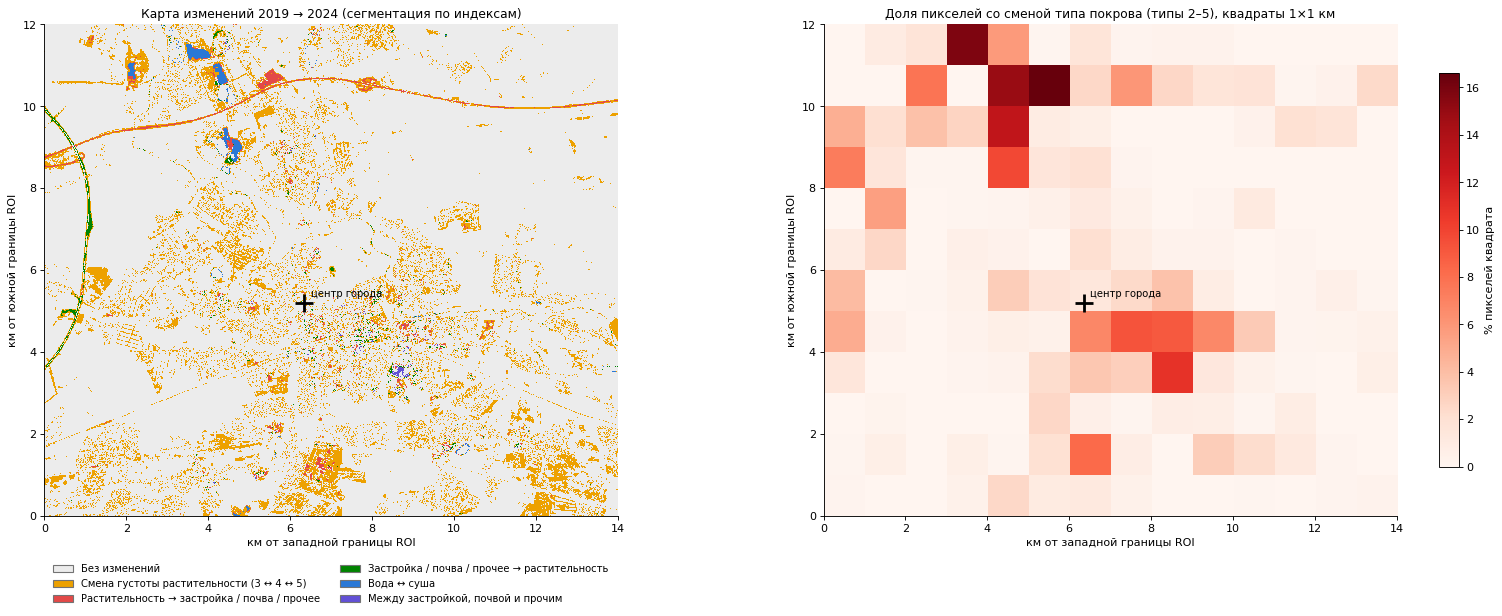

Квадраты 1×1 км с наибольшей долей смены типа покрова:


,"Центр квадрата, км (x, y)","Широта, долгота",Положение,"Смена типа покрова, %","Все изменения, %",Преобладающий переход
№,,,,,,
1,"5.5, 10.5","55.8307, 38.6360",5.4 км на С от центра,16.6,34.7,Густая растительность → Застройка
2,"3.5, 11.5","55.8396, 38.6040",6.9 км на СЗ от центра,15.8,34.4,Умеренная растительность → Вода
3,"4.5, 10.5","55.8307, 38.6201",5.6 км на С от центра,14.8,41.3,Густая растительность → Вода
4,"4.5, 9.5","55.8217, 38.6201",4.7 км на СЗ от центра,13.0,31.9,Густая растительность → Вода
5,"8.5, 3.5","55.7680, 38.6844",2.7 км на ЮВ от центра,10.8,23.9,Застройка → Разреженная растительность
6,"4.5, 8.5","55.8127, 38.6202",3.8 км на СЗ от центра,9.8,18.7,Умеренная растительность → Вода
7,"7.5, 4.5","55.7769, 38.6684",1.3 км на ЮВ от центра,9.3,26.0,Застройка → Разреженная растительность
8,"8.5, 4.5","55.7769, 38.6843",2.3 км на В от центра,9.0,28.5,Застройка → Разреженная растительность


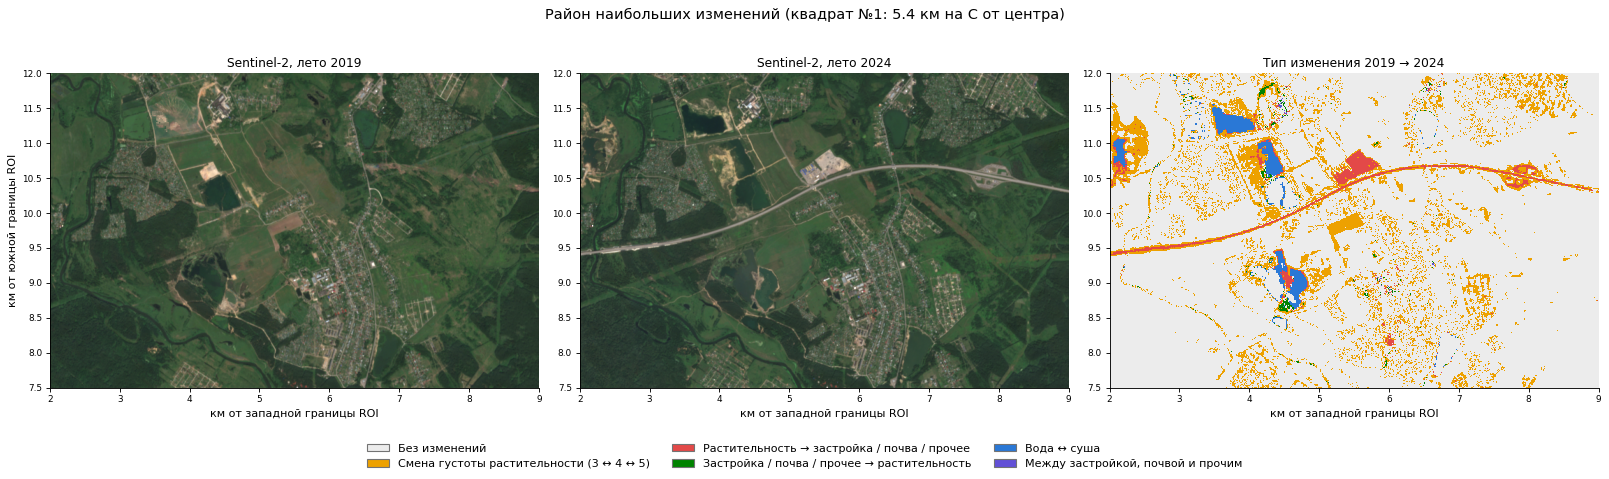

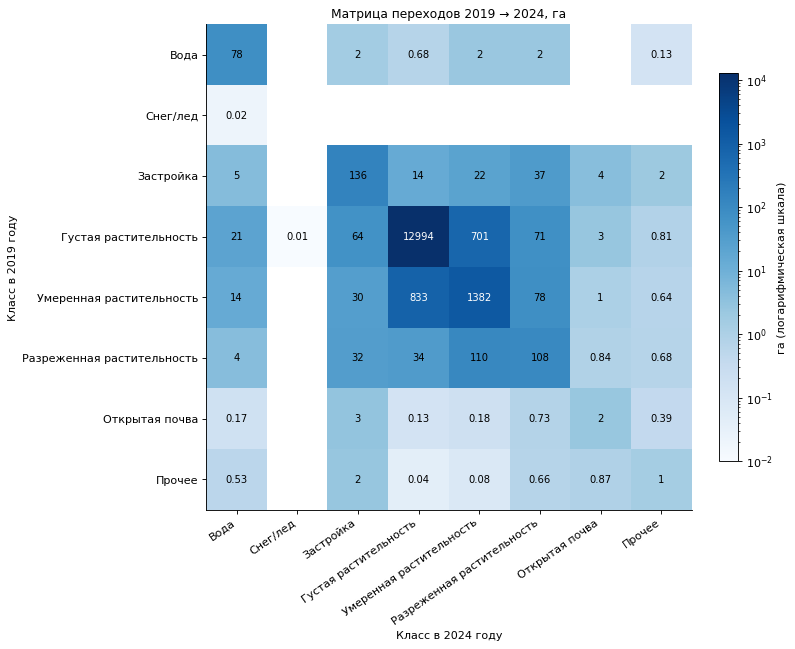

In [23]:
Y0, Y1 = YEARS[0], YEARS[-1]
a, b = seg[Y0], seg[Y1]
valid = (a != SEG_NODATA) & (b != SEG_NODATA)
changed = valid & (a != b)

# ---- Матрица переходов: площадь (га), перешедшая из класса 2019 года (строка) в класс 2024 года (столбец)
n_cls = len(SEG_CLASS_NAMES)
transition = np.bincount(a[valid].astype(int) * n_cls + b[valid], minlength=n_cls ** 2).reshape(n_cls, n_cls)
transition_ha = pd.DataFrame(transition * PIXEL_HA,
                             index=pd.Index(SEG_CLASS_NAMES, name=f'{Y0} ↓ / {Y1} →'),
                             columns=SEG_CLASS_NAMES)
print(f"Пикселей, сменивших класс с {Y0} по {Y1} год: {changed.sum():,} "
      f"({changed.sum() / valid.sum() * 100:.1f}% ROI, {changed.sum() * PIXEL_HA:,.0f} га)".replace(',', ' '))
print("\nМатрица переходов, га:")
display(transition_ha.round(1))
transition_ha.to_csv(os.path.join(RESULTS_DIR, 'transition_matrix_segmentation_ha.csv'), encoding='utf-8-sig')

# ---- Основные переходы (вне диагонали)
pairs = [(SEG_CLASS_NAMES[i], SEG_CLASS_NAMES[j], transition_ha.iat[i, j])
         for i in range(n_cls) for j in range(n_cls) if i != j and transition[i, j] > 0]
top_transitions = pd.DataFrame(pairs, columns=[f'Класс {Y0}', f'Класс {Y1}', 'Площадь, га'])
top_transitions['% от всех изменений'] = top_transitions['Площадь, га'] / (changed.sum() * PIXEL_HA) * 100
top_transitions = top_transitions.sort_values('Площадь, га', ascending=False).head(10).reset_index(drop=True)
top_transitions.index += 1
print("10 крупнейших переходов:")
display(top_transitions.round(2))

# ---- Тип изменения для каждого пикселя
VEG = [3, 4, 5]
veg_a, veg_b = np.isin(a, VEG), np.isin(b, VEG)
CHANGE_TYPES = ['Без изменений',
                'Смена густоты растительности (3 ↔ 4 ↔ 5)',
                'Растительность → застройка / почва / прочее',
                'Застройка / почва / прочее → растительность',
                'Вода ↔ суша',
                'Между застройкой, почвой и прочим']
CHANGE_COLORS = ['#ececec', '#eda100', '#e34948', '#008300', '#2a78d6', '#6250d6']
change_type = np.full(a.shape, 255, dtype=np.uint8)
change_type[valid & ~changed] = 0
t_density = changed & veg_a & veg_b
t_water = changed & ~t_density & ((a == 0) | (b == 0))
t_loss = changed & ~t_density & ~t_water & veg_a
t_gain = changed & ~t_density & ~t_water & veg_b
t_other = changed & ~(t_density | t_water | t_loss | t_gain)
for code, mask in enumerate([t_density, t_loss, t_gain, t_water, t_other], start=1):
    change_type[mask] = code

change_summary = pd.DataFrame({
    'Площадь, га': [(change_type == k).sum() * PIXEL_HA for k in range(len(CHANGE_TYPES))],
}, index=pd.Index(CHANGE_TYPES, name='Тип изменения'))
change_summary['% ROI'] = change_summary['Площадь, га'] / (valid.sum() * PIXEL_HA) * 100
change_summary['% от всех изменений'] = change_summary['Площадь, га'] / (changed.sum() * PIXEL_HA) * 100
change_summary.loc['Без изменений', '% от всех изменений'] = np.nan
display(change_summary.round(2))

# ---- Где сосредоточены изменения: доля пикселей с изменением типа 2–5 («смена типа покрова»,
# без колебаний густоты растительности) в квадратах 1×1 км
BLOCK = int(1000 / SCALE)                     # 100 пикселей = 1 км


def block_share(mask, valid_mask, block=BLOCK):
    h, w = mask.shape
    hh, ww = h // block * block, w // block * block
    num = mask[:hh, :ww].reshape(hh // block, block, ww // block, block).sum(axis=(1, 3))
    den = valid_mask[:hh, :ww].reshape(hh // block, block, ww // block, block).sum(axis=(1, 3))
    return num / np.maximum(den, 1) * 100


def direction_from_town(x_km, y_km):
    """Расстояние и направление (румб) от центра города до точки (км от ЮЗ угла ROI)."""
    dx, dy = x_km - TOWN_KM[0], y_km - TOWN_KM[1]
    dist = np.hypot(dx, dy)
    if dist < 1:
        return 'центр города'
    rumbs = ['В', 'СВ', 'С', 'СЗ', 'З', 'ЮЗ', 'Ю', 'ЮВ']
    angle = np.degrees(np.arctan2(dy, dx)) % 360
    return f'{dist:.1f} км на {rumbs[int(((angle + 22.5) % 360) // 45)]} от центра'


land_change = np.isin(change_type, [2, 3, 4, 5])
block_land = block_share(land_change, valid)
block_any = block_share(changed, valid)

fig, axes = plt.subplots(1, 2, figsize=(19, 7.6), constrained_layout=True)
change_cmap = ListedColormap(CHANGE_COLORS)
change_cmap.set_bad('black')
change_norm = BoundaryNorm(np.arange(-0.5, len(CHANGE_TYPES)), len(CHANGE_TYPES))
change_handles = [Patch(facecolor=c, edgecolor='0.45', label=n) for c, n in zip(CHANGE_COLORS, CHANGE_TYPES)]
axes[0].imshow(np.ma.masked_equal(change_type, 255), cmap=change_cmap, norm=change_norm,
               extent=EXTENT_KM, interpolation='nearest')
axes[0].set_title(f'Карта изменений {Y0} → {Y1} (сегментация по индексам)')
axes[0].legend(handles=change_handles, loc='upper center', bbox_to_anchor=(0.5, -0.08), ncol=2,
               frameon=False, fontsize=9)
im = axes[1].imshow(block_land, cmap='Reds', extent=EXTENT_KM, vmin=0)
axes[1].set_title('Доля пикселей со сменой типа покрова (типы 2–5), квадраты 1×1 км')
fig.colorbar(im, ax=axes[1], shrink=0.8, label='% пикселей квадрата')
for ax in axes:
    ax.plot(*TOWN_KM, marker='+', color='black', ms=16, mew=2.5)
    ax.annotate('центр города', TOWN_KM, xytext=(6, 6), textcoords='offset points', fontsize=9)
    ax.set_xlabel('км от западной границы ROI')
    ax.set_ylabel('км от южной границы ROI')
plt.show()

# ---- Квадраты с наибольшей долей смены типа покрова
n_rows_b = block_land.shape[0]
order = np.argsort(block_land, axis=None)[::-1][:8]
hot_rows = []
for flat in order:
    i, j = np.unravel_index(flat, block_land.shape)
    x_km, y_km = j + 0.5, n_rows_b - i - 0.5
    lon, lat = warp_transform(ROI_CRS, 'EPSG:4326', [xmin + x_km * 1000], [ymin + y_km * 1000])
    rows_sl = slice(i * BLOCK, (i + 1) * BLOCK)
    cols_sl = slice(j * BLOCK, (j + 1) * BLOCK)
    m = land_change[rows_sl, cols_sl]
    codes = a[rows_sl, cols_sl][m].astype(int) * n_cls + b[rows_sl, cols_sl][m]
    top = np.bincount(codes, minlength=n_cls ** 2).argmax()
    hot_rows.append({
        'Центр квадрата, км (x, y)': f'{x_km:.1f}, {y_km:.1f}',
        'Широта, долгота': f'{lat[0]:.4f}, {lon[0]:.4f}',
        'Положение': direction_from_town(x_km, y_km),
        'Смена типа покрова, %': block_land[i, j],
        'Все изменения, %': block_any[i, j],
        'Преобладающий переход': f'{SEG_CLASS_NAMES[top // n_cls]} → {SEG_CLASS_NAMES[top % n_cls]}',
    })
hot_blocks = pd.DataFrame(hot_rows, index=pd.RangeIndex(1, len(hot_rows) + 1, name='№'))
print("Квадраты 1×1 км с наибольшей долей смены типа покрова:")
display(hot_blocks.round(1))

# ---- Крупный план района вокруг квадрата №1: композиты первого и последнего года и тип изменения
i0, j0 = np.unravel_index(order[0], block_land.shape)
cx, cy = j0 + 0.5, n_rows_b - i0 - 0.5                     # центр квадрата, км
half_w, half_h = 3.5, 2.25                                  # окно 7 × 4.5 км
zx0 = min(max(cx - half_w, 0), ROI_WIDTH_KM - 2 * half_w)
zy0 = min(max(cy - half_h, 0), ROI_HEIGHT_KM - 2 * half_h)
zoom_extent = [zx0, zx0 + 2 * half_w, zy0, zy0 + 2 * half_h]
px_per_km = 1000 / SCALE
zoom = (slice(int(round((ROI_HEIGHT_KM - zoom_extent[3]) * px_per_km)),
              int(round((ROI_HEIGHT_KM - zoom_extent[2]) * px_per_km))),
        slice(int(round(zoom_extent[0] * px_per_km)), int(round(zoom_extent[1] * px_per_km))))

fig, axes = plt.subplots(1, 3, figsize=(20, 5.9), constrained_layout=True)
axes[0].imshow(to_rgb(s2[Y0])[zoom], extent=zoom_extent)
axes[0].set_title(f'Sentinel-2, лето {Y0}')
axes[1].imshow(to_rgb(s2[Y1])[zoom], extent=zoom_extent)
axes[1].set_title(f'Sentinel-2, лето {Y1}')
axes[2].imshow(np.ma.masked_equal(change_type[zoom], 255), cmap=change_cmap, norm=change_norm,
               extent=zoom_extent, interpolation='nearest')
axes[2].set_title(f'Тип изменения {Y0} → {Y1}')
for ax in axes:
    ax.set_xlabel('км от западной границы ROI')
    ax.tick_params(labelsize=8)
axes[0].set_ylabel('км от южной границы ROI')
fig.legend(handles=change_handles, loc='outside lower center', ncol=3, frameon=False)
fig.suptitle(f'Район наибольших изменений (квадрат №1: {hot_blocks.loc[1, "Положение"]})', fontsize=13)
plt.show()

# ---- Матрица переходов в виде тепловой карты (логарифмическая шкала: диагональ на порядки больше)
fig, ax = plt.subplots(figsize=(10, 8), constrained_layout=True)
values = transition_ha.values
im = ax.imshow(np.where(values > 0, values, np.nan), cmap='Blues',
               norm=LogNorm(vmin=max(values[values > 0].min(), 0.01), vmax=values.max()))
for i in range(n_cls):
    for j in range(n_cls):
        if values[i, j] > 0:
            ax.text(j, i, f'{values[i, j]:.0f}' if values[i, j] >= 1 else f'{values[i, j]:.2f}',
                    ha='center', va='center', fontsize=9,
                    color='white' if values[i, j] > values.max() / 30 else 'black')
ax.set_xticks(range(n_cls), SEG_CLASS_NAMES, rotation=35, ha='right')
ax.set_yticks(range(n_cls), SEG_CLASS_NAMES)
ax.set_xlabel(f'Класс в {Y1} году')
ax.set_ylabel(f'Класс в {Y0} году')
ax.set_title(f'Матрица переходов {Y0} → {Y1}, га')
fig.colorbar(im, ax=ax, shrink=0.8, label='га (логарифмическая шкала)')
plt.show()

## **7. Сравнение с картами Dynamic World**

### **7.1. Рассчитать площади всех классов для каждого года по картам классификации**



In [24]:
dw_pixel_counts = pd.DataFrame(
    {year: count_classes(dw[year], len(DW_CLASS_NAMES), DW_NODATA)[1] for year in YEARS},
    index=pd.Index(DW_CLASS_NAMES, name='Класс'))
print("Пикселей без данных в картах DW:", {y: int((dw[y] == DW_NODATA).sum()) for y in YEARS})

dw_areas = area_tables(dw_pixel_counts)
dw_area_ha = dw_areas['ha']
print("\nКоличество пикселей каждого класса Dynamic World:")
display(dw_pixel_counts)
print("Площадь классов, га:")
display(dw_area_ha.round(1))
print("Площадь классов, км²:")
display(dw_areas['km2'].round(3))
print("Доля от площади ROI, %:")
display(dw_areas['pct'].round(2))
dw_pixel_counts.to_csv(os.path.join(RESULTS_DIR, 'dynamicworld_pixel_counts.csv'), encoding='utf-8-sig')

Пикселей без данных в картах DW: {2019: 0, 2020: 0, 2021: 0, 2022: 0, 2023: 0, 2024: 0}

Количество пикселей каждого класса Dynamic World:


,2019,2020,2021,2022,2023,2024
Класс,,,,,,
Вода,28812,39497,32637,31970,32435,34026
Деревья,1117880,1051680,1060275,995385,1070224,1079267
Трава,90825,103642,82867,119099,74912,62029
Затопл. растительность,820,11625,3275,3270,2676,2216
Культуры,38033,54603,50368,57458,42002,35560
Кустарники,10868,5428,10155,12150,16442,8226
Застройка,389137,409407,429250,449779,437277,456950
Голая земля,3618,4094,11173,10889,4032,1726
Снег и лед,7,24,0,0,0,0


Площадь классов, га:


,2019,2020,2021,2022,2023,2024
Класс,,,,,,
Вода,288.1,395.0,326.4,319.7,324.4,340.3
Деревья,11178.8,10516.8,10602.8,9953.8,10702.2,10792.7
Трава,908.2,1036.4,828.7,1191.0,749.1,620.3
Затопл. растительность,8.2,116.2,32.8,32.7,26.8,22.2
Культуры,380.3,546.0,503.7,574.6,420.0,355.6
Кустарники,108.7,54.3,101.6,121.5,164.4,82.3
Застройка,3891.4,4094.1,4292.5,4497.8,4372.8,4569.5
Голая земля,36.2,40.9,111.7,108.9,40.3,17.3
Снег и лед,0.1,0.2,0.0,0.0,0.0,0.0


Площадь классов, км²:


,2019,2020,2021,2022,2023,2024
Класс,,,,,,
Вода,2.881,3.950,3.264,3.197,3.244,3.403
Деревья,111.788,105.168,106.028,99.538,107.022,107.927
Трава,9.082,10.364,8.287,11.910,7.491,6.203
Затопл. растительность,0.082,1.162,0.328,0.327,0.268,0.222
Культуры,3.803,5.460,5.037,5.746,4.200,3.556
Кустарники,1.087,0.543,1.016,1.215,1.644,0.823
Застройка,38.914,40.941,42.925,44.978,43.728,45.695
Голая земля,0.362,0.409,1.117,1.089,0.403,0.173
Снег и лед,0.001,0.002,0.000,0.000,0.000,0.000


Доля от площади ROI, %:


,2019,2020,2021,2022,2023,2024
Класс,,,,,,
Вода,1.72,2.35,1.94,1.90,1.93,2.03
Деревья,66.54,62.60,63.11,59.25,63.70,64.24
Трава,5.41,6.17,4.93,7.09,4.46,3.69
Затопл. растительность,0.05,0.69,0.19,0.19,0.16,0.13
Культуры,2.26,3.25,3.00,3.42,2.50,2.12
Кустарники,0.65,0.32,0.60,0.72,0.98,0.49
Застройка,23.16,24.37,25.55,26.77,26.03,27.20
Голая земля,0.22,0.24,0.67,0.65,0.24,0.10
Снег и лед,0.00,0.00,0.00,0.00,0.00,0.00


### **7.2. Построить графики динамики изменений для каждого класса по картам классификации**



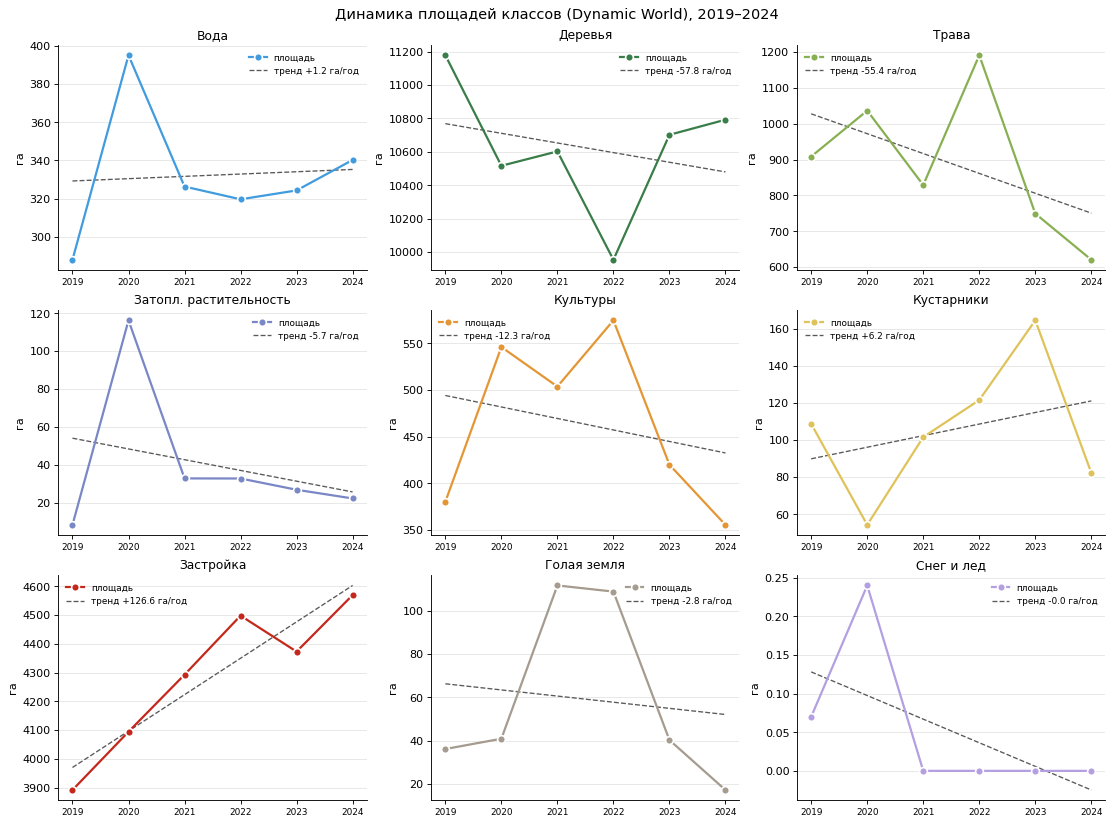

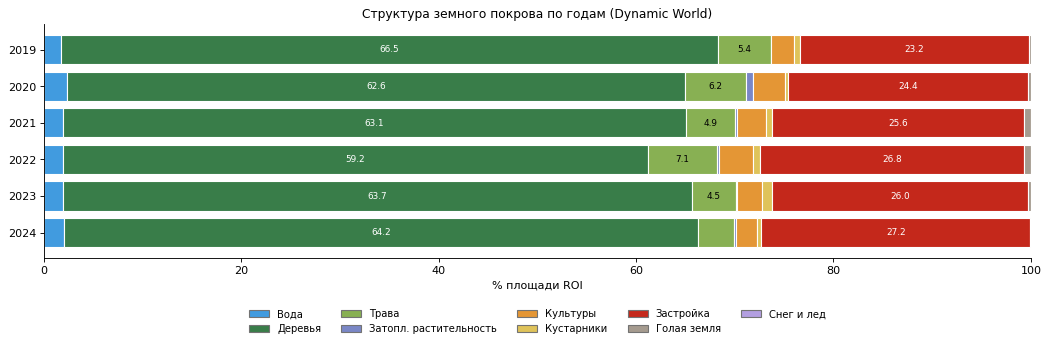

In [25]:
plot_dynamics(dw_area_ha, DW_COLORS, 'Динамика площадей классов (Dynamic World), 2019–2024', ncols=3)
plot_structure(dw_area_ha, DW_COLORS, 'Структура земного покрова по годам (Dynamic World)')

### **7.3. Рассчитать все статистические показатели по картам классификации**



In [26]:
print("1. Абсолютные показатели (Dynamic World):")
display(absolute_table(dw_pixel_counts))

dw_stats = dynamics_stats(dw_area_ha)
print("2–3. Показатели изменений и статистика временного ряда:")
display(dw_stats.round(2))

1. Абсолютные показатели (Dynamic World):


2019     2020     2021    2022     2023     2024
Класс                  Показатель                                                     
Вода                   пикселей      28812    39497    32637   31970    32435    34026
                       га            288.1    395.0    326.4   319.7    324.4    340.3
                       км²           2.881     3.95    3.264   3.197    3.244    3.403
                       % ROI          1.72     2.35     1.94     1.9     1.93     2.03
Деревья                пикселей    1117880  1051680  1060275  995385  1070224  1079267
                       га          11178.8  10516.8  10602.8  9953.8  10702.2  10792.7
                       км²         111.788  105.168  106.028  99.538  107.022  107.927
                       % ROI         66.54     62.6    63.11   59.25     63.7    64.24
Трава                  пикселей      90825   103642    82867  119099    74912    62029
                       га            908.2   1036.4    828.7  1191.0    749.1    620.3
                       км²           9.082   10.364    8.287   11.91    7.491    6.203
                       % ROI          5.41     6.17     4.93    7.09     4.46     3.69
Затопл. растительность пикселей        820    11625     3275    3270     2676     2216
                       га              8.2    116.2     32.8    32.7     26.8     22.2
                       км²           0.082    1.162    0.328   0.327    0.268    0.222
                       % ROI          0.05     0.69     0.19    0.19     0.16     0.13
Культуры               пикселей      38033    54603    50368   57458    42002    35560
                       га            380.3    546.0    503.7   574.6    420.0    355.6
                       км²           3.803     5.46    5.037   5.746      4.2    3.556
                       % ROI          2.26     3.25      3.0    3.42      2.5     2.12
Кустарники             пикселей      10868     5428    10155   12150    16442     8226
                       га            108.7     54.3    101.6   121.5    164.4     82.3
                       км²           1.087    0.543    1.016   1.215    1.644    0.823
                       % ROI          0.65     0.32      0.6    0.72     0.98     0.49
Застройка              пикселей     389137   409407   429250  449779   437277   456950
                       га           3891.4   4094.1   4292.5  4497.8   4372.8   4569.5
                       км²          38.914   40.941   42.925  44.978   43.728   45.695
                       % ROI         23.16    24.37    25.55   26.77    26.03     27.2
Голая земля            пикселей       3618     4094    11173   10889     4032     1726
                       га             36.2     40.9    111.7   108.9     40.3     17.3
                       км²           0.362    0.409    1.117   1.089    0.403    0.173
                       % ROI          0.22     0.24     0.67    0.65     0.24      0.1
Снег и лед             пикселей          7       24        0       0        0        0
                       га              0.1      0.2      0.0     0.0      0.0      0.0
                       км²           0.001    0.002      0.0     0.0      0.0      0.0
                       % ROI           0.0      0.0      0.0     0.0      0.0      0.0

2–3. Показатели изменений и статистика временного ряда:


,"S_2019, га","S_2024, га","ΔS, га","Δ, %","Прирост, га/год","Темп, %/год","Среднее, га","σ, га","CV, %","Наклон тренда, га/год",R²
Вода,288.12,340.26,52.14,18.10,10.43,3.38,332.30,32.15,9.67,1.20,0.00
Деревья,11178.80,10792.67,-386.13,-3.45,-77.23,-0.70,10624.52,365.93,3.44,-57.81,0.07
Трава,908.25,620.29,-287.96,-31.70,-57.59,-7.34,888.96,186.51,20.98,-55.41,0.26
Затопл. растительность,8.20,22.16,13.96,170.24,2.79,22.00,39.80,35.18,88.38,-5.68,0.08
Культуры,380.33,355.60,-24.73,-6.50,-4.95,-1.34,463.37,82.88,17.89,-12.31,0.06
Кустарники,108.68,82.26,-26.42,-24.31,-5.28,-5.42,105.45,33.95,32.20,6.24,0.10
Застройка,3891.37,4569.50,678.13,17.43,135.63,3.27,4286.33,232.87,5.43,126.63,0.86
Голая земля,36.18,17.26,-18.92,-52.29,-3.78,-13.76,59.22,36.98,62.45,-2.84,0.02
Снег и лед,0.07,0.00,-0.07,-100.00,-0.01,-100.00,0.05,0.09,170.36,-0.03,0.35


### **7.4. Определить какие классы показали наибольшие изменения по картам классификации**



In [27]:
dw_sig = significant_changes(dw_stats)
display(dw_sig.round(2))
describe_significant(dw_sig)

,Ранг по |Δ%|,"ΔS, га","Δ, %","Наклон тренда, га/год",R²,|Δ%| > 10%,|ΔS| > 10 га,R² ≥ 0.5,Значимое изменение
Затопл. растительность,1,13.96,170.24,-5.68,0.08,True,True,False,False
Снег и лед,2,-0.07,-100.00,-0.03,0.35,True,False,False,False
Голая земля,3,-18.92,-52.29,-2.84,0.02,True,True,False,False
Трава,4,-287.96,-31.70,-55.41,0.26,True,True,False,False
Кустарники,5,-26.42,-24.31,6.24,0.10,True,True,False,False
Вода,6,52.14,18.10,1.20,0.00,True,True,False,False
Застройка,7,678.13,17.43,126.63,0.86,True,True,True,True
Культуры,8,-24.73,-6.50,-12.31,0.06,False,True,False,False
Деревья,9,-386.13,-3.45,-57.81,0.07,False,True,False,False


1. Затопл. растительность: ΔS = +14.0 га (+170.2%), R² = 0.08 — изменение > 10% и > 10 га, но R² = 0.08 < 0.5 — межгодовые колебания
2. Снег и лед: ΔS = -0.1 га (-100.0%), R² = 0.35 — изменение ниже порогов значимости
3. Голая земля: ΔS = -18.9 га (-52.3%), R² = 0.02 — изменение > 10% и > 10 га, но R² = 0.02 < 0.5 — межгодовые колебания
4. Трава: ΔS = -288.0 га (-31.7%), R² = 0.26 — изменение > 10% и > 10 га, но R² = 0.26 < 0.5 — межгодовые колебания
5. Кустарники: ΔS = -26.4 га (-24.3%), R² = 0.10 — изменение > 10% и > 10 га, но R² = 0.10 < 0.5 — межгодовые колебания
6. Вода: ΔS = +52.1 га (+18.1%), R² = 0.00 — изменение > 10% и > 10 га, но R² = 0.00 < 0.5 — межгодовые колебания
7. Застройка: ΔS = +678.1 га (+17.4%), R² = 0.86 — ЗНАЧИМОЕ направленное изменение
8. Культуры: ΔS = -24.7 га (-6.5%), R² = 0.06 — изменение ниже порогов значимости
9. Деревья: ΔS = -386.1 га (-3.5%), R² = 0.07 — изменение ниже порогов значимости


### **7.5. Создать сводную таблицу результатов по картам классификации**



In [28]:
dw_summary = summary_table(dw_area_ha, dw_sig,
                           extra_rows={'Растительность, всего (1–5)': DW_CLASS_NAMES[1:6]})
display(dw_summary)
dw_summary.to_csv(os.path.join(RESULTS_DIR, 'summary_dynamicworld.csv'), encoding='utf-8-sig')

,S_2019 (га),S_2024 (га),ΔS (га),Δ%,Темп (%/год),Тренд,Наклон (га/год),CV (%),R²
Класс,,,,,,,,,
Вода,288.12,340.26,52.14,18.10,3.38,→,1.20,9.67,0.00
Деревья,11178.80,10792.67,-386.13,-3.45,-0.70,→,-57.81,3.44,0.07
Трава,908.25,620.29,-287.96,-31.70,-7.34,→,-55.41,20.98,0.26
Затопл. растительность,8.20,22.16,13.96,170.24,22.00,→,-5.68,88.38,0.08
Культуры,380.33,355.60,-24.73,-6.50,-1.34,→,-12.31,17.89,0.06
Кустарники,108.68,82.26,-26.42,-24.31,-5.42,→,6.24,32.20,0.10
Застройка,3891.37,4569.50,678.13,17.43,3.27,↑,126.63,5.43,0.86
Голая земля,36.18,17.26,-18.92,-52.29,-13.76,→,-2.84,62.45,0.02
Снег и лед,0.07,0.00,-0.07,-100.00,-100.00,→,-0.03,170.36,0.35


## **8. Сравнение результатов полученных по результатам сегментации и картам классификаций**

**Задание:** Сведите классы обоих методов к укрупнённым классам по таблице 10. Сравните площади укрупнённых классов по годам, рассчитайте долю совпадающих пикселей для каждого года и матрицу совпадений для 2024 года.

#### **Таблица 10. Соответствие классов сегментации и Dynamic World**

| **Укрупнённый класс** | **Метки сегментации** | **Классы Dynamic World** |
|---|---|---|
| Вода | 0 | 0 — Вода |
| Снег/лед | 1 | 8 — Снег и лед |
| Застройка | 2 | 6 — Застройка |
| Растительность | 3, 4, 5 | 1 — Деревья, 2 — Трава, 3 — Затопл. растительность, 4 — Культуры, 5 — Кустарники |
| Открытая почва | 6 | 7 — Голая земля |
| Прочее | 7 | — |

Площади укрупненных классов, га:


Год                      2019                      2020                      2021                      2022                      2023                      2024              
Метод             Сегментация Dynamic World Сегментация Dynamic World Сегментация Dynamic World Сегментация Dynamic World Сегментация Dynamic World Сегментация Dynamic World
Укрупненный класс                                                                                                                                                            
Вода                     84.8         288.1        70.7         393.7        98.2         326.4       106.2         319.7       109.0         324.4       122.4         340.3
Снег/лед                  0.0           0.1         0.2           0.2         0.0           0.0         0.1           0.0         0.0           0.0         0.0           0.0
Застройка               219.7        3891.4       230.9        4094.0       393.8        4292.5       406.6        4497.8       320.4        4372.8       268.0        4569.5
Растительность        16482.6       12584.3     16481.7       12269.8     16293.1       12069.4     16267.9       11873.6     16352.5       12062.6     16391.7       11873.0
Открытая почва            6.8          36.2         6.6          40.9         9.3         111.7        12.4         108.9        10.7          40.3        11.8          17.3
Прочее                    6.1           0.0         8.6           0.0         5.6           0.0         6.8           0.0         7.3           0.0         6.1           0.0

Разность площадей «сегментация − Dynamic World», га:


,2019,2020,2021,2022,2023,2024
Вода,-203.3,-323.0,-228.2,-213.5,-215.3,-217.8
Снег/лед,-0.0,-0.1,0.0,0.1,0.0,0.0
Застройка,-3671.7,-3863.1,-3898.7,-4091.2,-4052.4,-4301.5
Растительность,3898.3,4211.9,4223.7,4394.3,4290.0,4518.8
Открытая почва,-29.4,-34.3,-102.5,-96.4,-29.6,-5.5
Прочее,6.1,8.6,5.6,6.8,7.3,6.1


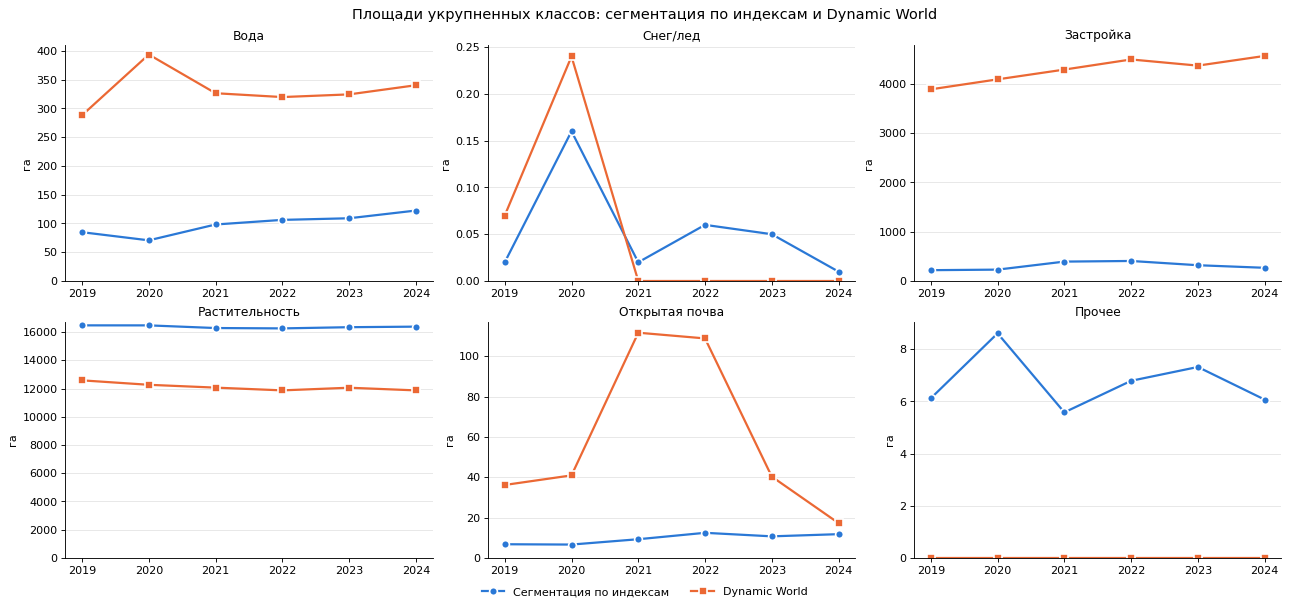

Согласованность методов по укрупненным классам:


,"Совпадающих пикселей, %",Каппа Коэна
Год,,
2019,76.250,0.093
2020,74.232,0.079
2021,73.365,0.104
2022,72.390,0.107
2023,73.611,0.109
2024,72.586,0.104


Среднее за 2019–2024: 73.7% совпадающих пикселей
Матрица совпадений 2024, га:


,Вода,Снег/лед,Застройка,Растительность,Открытая почва,Прочее
Сегментация ↓ / DW →,,,,,,
Вода,122.0,0.0,0.3,0.2,0.0,0.0
Снег/лед,0.0,0.0,0.0,0.0,0.0,0.0
Застройка,13.3,0.0,220.8,21.2,12.7,0.0
Растительность,203.8,0.0,4332.9,11851.1,4.0,0.0
Открытая почва,0.5,0.0,10.2,0.5,0.6,0.0
Прочее,0.7,0.0,5.4,0.0,0.0,0.0


Совпадение по укрупненным классам, 2024:


,"Сегментация, га","Dynamic World, га","Совпадает, га",% от площади DW,% от площади сегментации
Вода,122.4,340.3,122.0,35.9,99.6
Снег/лед,0.0,0.0,0.0,NaN,0.0
Застройка,268.0,4569.5,220.8,4.8,82.4
Растительность,16391.7,11873.0,11851.1,99.8,72.3
Открытая почва,11.8,17.3,0.6,3.4,4.9
Прочее,6.1,0.0,0.0,NaN,0.0


Сравнение трендов укрупненных классов:


,Δ% (сегм.),"Наклон, га/год (сегм.)",R² (сегм.),Тренд (сегм.),Δ% (DW),"Наклон, га/год (DW)",R² (DW),Тренд (DW)
Вода,44.36,8.89,0.81,↑,18.10,1.32,0.01,→
Снег/лед,-50.00,-0.01,0.11,→,-100.00,-0.03,0.35,→
Застройка,21.97,14.93,0.12,→,17.43,126.64,0.86,↑
Растительность,-0.55,-24.77,0.26,→,-5.65,-124.97,0.75,→
Открытая почва,73.86,1.15,0.75,→,-52.29,-2.84,0.02,→
Прочее,-0.82,-0.08,0.02,→,NaN,0.00,NaN,→


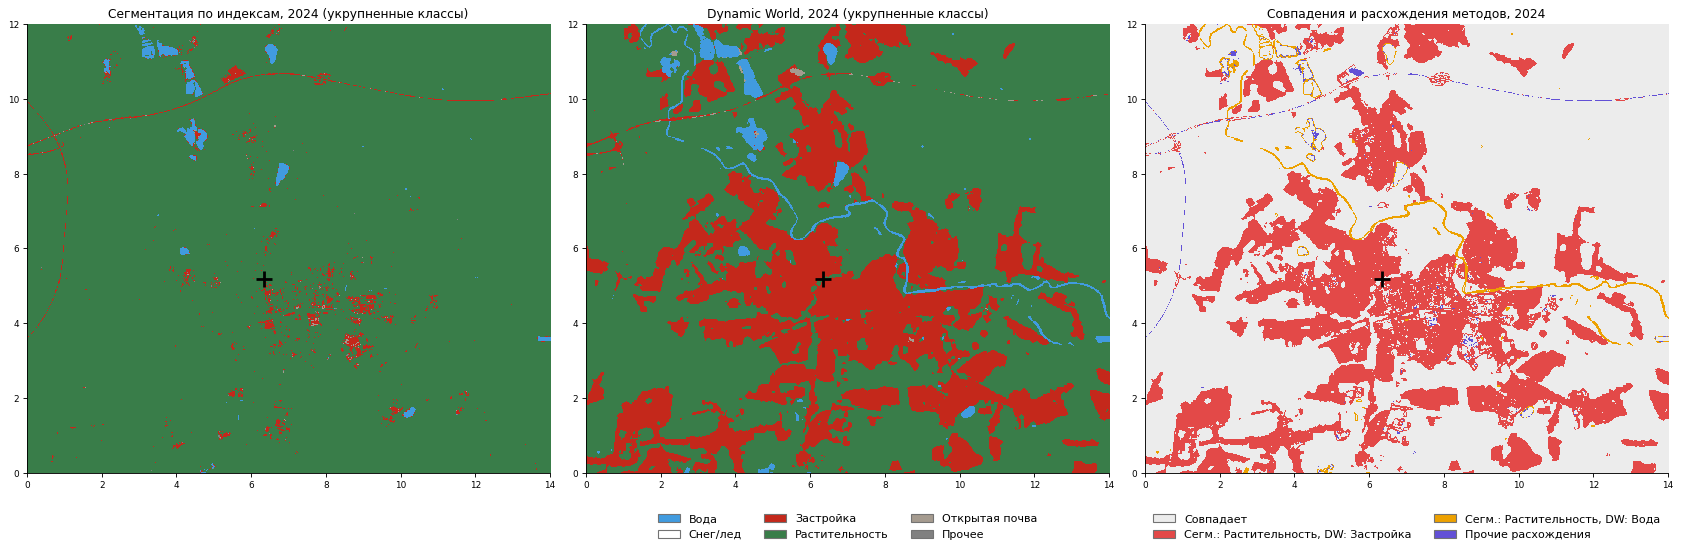

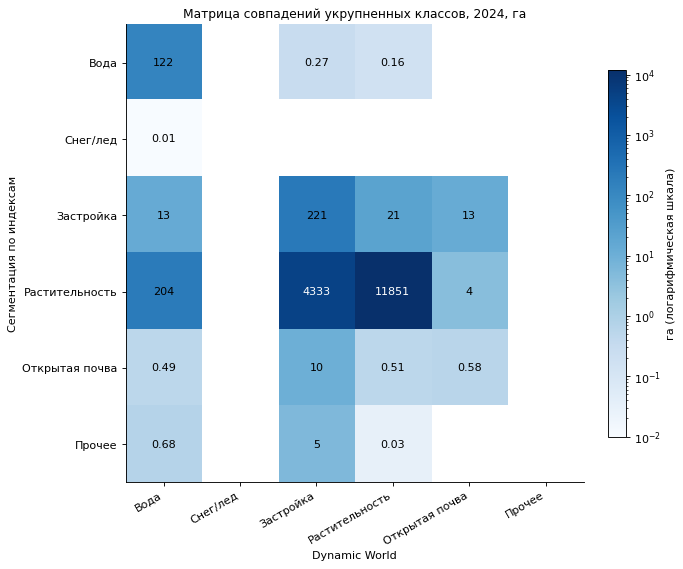

In [29]:
# ---- Укрупненные классы (таблица 10)
AGG_NAMES = ['Вода', 'Снег/лед', 'Застройка', 'Растительность', 'Открытая почва', 'Прочее']
AGG_COLORS = ['#419bdf', '#ffffff', '#c4281b', '#397d49', '#a59b8f', '#808080']
AGG_NODATA = 255
SEG_TO_AGG = np.array([0, 1, 2, 3, 3, 3, 4, 5], dtype=np.uint8)     # индекс — метка сегментации 0–7
DW_TO_AGG = np.array([0, 3, 3, 3, 3, 3, 2, 4, 1], dtype=np.uint8)   # индекс — класс Dynamic World 0–8
n_agg = len(AGG_NAMES)


def to_agg(labels, lut, nodata):
    """Переводит метки в укрупненные классы через таблицу соответствия."""
    out = np.full(labels.shape, AGG_NODATA, dtype=np.uint8)
    ok = labels != nodata
    out[ok] = lut[labels[ok].astype(int)]
    return out


agg_seg = {y: to_agg(seg[y], SEG_TO_AGG, SEG_NODATA) for y in YEARS}
agg_dw = {y: to_agg(dw[y], DW_TO_AGG, DW_NODATA) for y in YEARS}
both_valid = {y: (agg_seg[y] != AGG_NODATA) & (agg_dw[y] != AGG_NODATA) for y in YEARS}

# ---- 8.1. Площади укрупненных классов по годам (по пикселям, где есть данные обоих методов)
agg_area_seg = pd.DataFrame({y: np.bincount(agg_seg[y][both_valid[y]], minlength=n_agg) * PIXEL_HA
                             for y in YEARS}, index=AGG_NAMES)
agg_area_dw = pd.DataFrame({y: np.bincount(agg_dw[y][both_valid[y]], minlength=n_agg) * PIXEL_HA
                            for y in YEARS}, index=AGG_NAMES)
agg_compare = pd.DataFrame({(y, method): table[y] for y in YEARS
                            for method, table in (('Сегментация', agg_area_seg), ('Dynamic World', agg_area_dw))})
agg_compare.columns.names = ['Год', 'Метод']
agg_compare.index.name = 'Укрупненный класс'
print("Площади укрупненных классов, га:")
display(agg_compare.round(1))
print("Разность площадей «сегментация − Dynamic World», га:")
display((agg_area_seg - agg_area_dw).round(1))

METHOD_COLORS = {'Сегментация по индексам': '#2a78d6', 'Dynamic World': '#eb6834'}
fig, axes = plt.subplots(2, 3, figsize=(16, 7.5), constrained_layout=True)
years_arr = np.array(YEARS)
for ax, name in zip(axes.flat, AGG_NAMES):
    for (label, color), table, marker in zip(METHOD_COLORS.items(), (agg_area_seg, agg_area_dw), ('o', 's')):
        ax.plot(years_arr, table.loc[name].values, color=color, lw=2, marker=marker, ms=7,
                markeredgecolor='white', markeredgewidth=1.5, label=label)
    ax.set_title(name)
    ax.set_xticks(years_arr)
    ax.set_ylabel('га')
    ax.set_ylim(bottom=0)
    ax.grid(axis='y', color='0.9')
handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='outside lower center', ncol=2, frameon=False)
fig.suptitle('Площади укрупненных классов: сегментация по индексам и Dynamic World', fontsize=13)
plt.show()

# ---- 8.2. Доля совпадающих пикселей по годам (и каппа Коэна — согласие с поправкой на случайное)
agree_rows = []
confusion = {}
for y in YEARS:
    s_, d_ = agg_seg[y][both_valid[y]].astype(int), agg_dw[y][both_valid[y]].astype(int)
    cm = np.bincount(s_ * n_agg + d_, minlength=n_agg ** 2).reshape(n_agg, n_agg)
    confusion[y] = cm
    total = cm.sum()
    p_o = np.trace(cm) / total
    p_e = (cm.sum(axis=1) * cm.sum(axis=0)).sum() / total ** 2
    agree_rows.append({'Год': y, 'Совпадающих пикселей, %': p_o * 100,
                       'Каппа Коэна': (p_o - p_e) / (1 - p_e)})
agreement = pd.DataFrame(agree_rows).set_index('Год')
print("Согласованность методов по укрупненным классам:")
display(agreement.round(3))
print(f"Среднее за 2019–2024: {agreement['Совпадающих пикселей, %'].mean():.1f}% совпадающих пикселей")

# ---- 8.3. Матрица совпадений за 2024 год, га (строки — сегментация, столбцы — Dynamic World)
cm_ha = pd.DataFrame(confusion[Y1] * PIXEL_HA,
                     index=pd.Index(AGG_NAMES, name='Сегментация ↓ / DW →'), columns=AGG_NAMES)
print(f"Матрица совпадений {Y1}, га:")
display(cm_ha.round(1))
cm_ha.to_csv(os.path.join(RESULTS_DIR, f'confusion_matrix_{Y1}_ha.csv'), encoding='utf-8-sig')

per_class = pd.DataFrame({
    'Сегментация, га': cm_ha.sum(axis=1),
    'Dynamic World, га': cm_ha.sum(axis=0),
    'Совпадает, га': np.diag(cm_ha.values),
})
with np.errstate(divide='ignore', invalid='ignore'):
    per_class['% от площади DW'] = per_class['Совпадает, га'] / per_class['Dynamic World, га'] * 100
    per_class['% от площади сегментации'] = per_class['Совпадает, га'] / per_class['Сегментация, га'] * 100
print(f"Совпадение по укрупненным классам, {Y1}:")
display(per_class.round(1))

# ---- 8.4. Сравнение трендов двух методов
seg_agg_stats = dynamics_stats(agg_area_seg)
dw_agg_stats = dynamics_stats(agg_area_dw)


def trend_arrow(stats_row):
    ok = (abs(stats_row['Δ, %']) > REL_THRESHOLD and abs(stats_row['ΔS, га']) > ABS_THRESHOLD_HA
          and stats_row['R²'] >= R2_THRESHOLD)
    return ('↑' if stats_row['Наклон тренда, га/год'] > 0 else '↓') if ok else '→'


trend_compare = pd.DataFrame({
    'Δ% (сегм.)': seg_agg_stats['Δ, %'],
    'Наклон, га/год (сегм.)': seg_agg_stats['Наклон тренда, га/год'],
    'R² (сегм.)': seg_agg_stats['R²'],
    'Тренд (сегм.)': [trend_arrow(r) for _, r in seg_agg_stats.iterrows()],
    'Δ% (DW)': dw_agg_stats['Δ, %'],
    'Наклон, га/год (DW)': dw_agg_stats['Наклон тренда, га/год'],
    'R² (DW)': dw_agg_stats['R²'],
    'Тренд (DW)': [trend_arrow(r) for _, r in dw_agg_stats.iterrows()],
})
print("Сравнение трендов укрупненных классов:")
display(trend_compare.round(2))

# ---- Тепловая карта матрицы совпадений и карта расхождений за 2024 год
off_diag = [(confusion[Y1][i, j], i, j) for i in range(n_agg) for j in range(n_agg) if i != j]
top_mismatch = sorted(off_diag, reverse=True)[:2]
MISMATCH_NAMES = ['Совпадает'] + [f'Сегм.: {AGG_NAMES[i]}, DW: {AGG_NAMES[j]}' for _, i, j in top_mismatch] \
                 + ['Прочие расхождения']
MISMATCH_COLORS = ['#ececec', '#e34948', '#eda100', '#6250d6']
s24, d24 = agg_seg[Y1], agg_dw[Y1]
mismatch = np.full(s24.shape, 255, dtype=np.uint8)
mismatch[both_valid[Y1] & (s24 == d24)] = 0
mismatch[both_valid[Y1] & (s24 != d24)] = 3
for k, (_, i, j) in enumerate(top_mismatch, start=1):
    mismatch[both_valid[Y1] & (s24 == i) & (d24 == j)] = k

fig, axes = plt.subplots(1, 3, figsize=(21, 7), constrained_layout=True)
agg_cmap = ListedColormap(AGG_COLORS)
agg_norm = BoundaryNorm(np.arange(-0.5, n_agg), n_agg)
for ax, arr, title in ((axes[0], s24, f'Сегментация по индексам, {Y1}'), (axes[1], d24, f'Dynamic World, {Y1}')):
    ax.imshow(np.ma.masked_equal(arr, AGG_NODATA), cmap=agg_cmap, norm=agg_norm,
              extent=EXTENT_KM, interpolation='nearest')
    ax.set_title(title + ' (укрупненные классы)')
axes[1].legend(handles=[Patch(facecolor=c, edgecolor='0.45', label=n) for c, n in zip(AGG_COLORS, AGG_NAMES)],
               loc='upper center', bbox_to_anchor=(0.5, -0.07), ncol=3, frameon=False)
mm_cmap = ListedColormap(MISMATCH_COLORS)
mm_cmap.set_bad('black')
axes[2].imshow(np.ma.masked_equal(mismatch, 255), cmap=mm_cmap, extent=EXTENT_KM, interpolation='nearest',
               norm=BoundaryNorm(np.arange(-0.5, 4), 4))
axes[2].set_title(f'Совпадения и расхождения методов, {Y1}')
axes[2].legend(handles=[Patch(facecolor=c, edgecolor='0.45', label=n) for c, n in zip(MISMATCH_COLORS, MISMATCH_NAMES)],
               loc='upper center', bbox_to_anchor=(0.5, -0.07), ncol=2, frameon=False)
for ax in axes:
    ax.plot(*TOWN_KM, marker='+', color='black', ms=14, mew=2.5)
    ax.tick_params(labelsize=8)
plt.show()

fig, ax = plt.subplots(figsize=(8.5, 7), constrained_layout=True)
values = cm_ha.values
im = ax.imshow(np.where(values > 0, values, np.nan), cmap='Blues',
               norm=LogNorm(vmin=max(values[values > 0].min(), 0.01), vmax=values.max()))
for i in range(n_agg):
    for j in range(n_agg):
        if values[i, j] > 0:
            ax.text(j, i, f'{values[i, j]:.0f}' if values[i, j] >= 1 else f'{values[i, j]:.2f}',
                    ha='center', va='center', fontsize=10,
                    color='white' if values[i, j] > values.max() / 30 else 'black')
ax.set_xticks(range(n_agg), AGG_NAMES, rotation=30, ha='right')
ax.set_yticks(range(n_agg), AGG_NAMES)
ax.set_xlabel('Dynamic World')
ax.set_ylabel('Сегментация по индексам')
ax.set_title(f'Матрица совпадений укрупненных классов, {Y1}, га')
fig.colorbar(im, ax=ax, shrink=0.8, label='га (логарифмическая шкала)')
plt.show()

## **9. Выводы**

В выводах обязательно отразить:
1. **Количественная оценка динамики** (с конкретными цифрами для каждого класса)
2. **Выявленные тренды** (растущие, убывающие, стабильные классы)
3. **Скорость изменений** (га/год и %/год для ключевых классов)
4. **Пространственные закономерности** (где происходят основные изменения)
5. **Согласованность методов** (доля совпадающих пикселей по укрупнённым классам в % и основные причины расхождений)

**Исходные данные.** Территория — г. Павловский Посад и окрестности: прямоугольник 14 × 12 км в проекции UTM 37N (EPSG:32637). Это 168 км², или 16 800 га, или 1 680 000 пикселей 10 × 10 м. Углы: ЮЗ — 55.7361° с.ш., 38.5493° в.д.; СВ — 55.8445° с.ш., 38.7716° в.д. Летние медианные композиты Sentinel-2 (облачность сцены < 20 %, маска облаков по SCL) построены по 4–12 снимкам за сезон. Самые слабые композиты:
- 2020 год — всего 4 снимка, 140 пикселей без безоблачных наблюдений, остаточная дымка;
- 2024 год — только снимки июля–августа.

Карты Dynamic World (DW) — мода по 19–26 картам за лето.

---

### 1. Количественная оценка динамики (2019 → 2024)

**Сегментация по спектральным индексам**

| Класс | S₂₀₁₉, га | S₂₀₂₄, га | ΔS, га | Δ, % | Темп, %/год | CV, % | R² | Тренд |
|---|---|---|---|---|---|---|---|---|
| Вода | 84.8 | 122.4 | +37.6 | +44.4 | +7.6 | 17.1 | 0.81 | ↑ |
| Застройка | 219.7 | 268.0 | +48.3 | +22.0 | +4.1 | 24.0 | 0.12 | → |
| Густая растительность | 13 854.1 | 13 875.9 | +21.8 | +0.2 | +0.03 | 1.9 | 0.06 | → |
| Умеренная растительность | 2 338.3 | 2 218.2 | −120.2 | −5.1 | −1.1 | 7.4 | 0.00 | → |
| Разреженная растительность | 290.1 | 297.7 | +7.6 | +2.6 | +0.5 | 12.1 | 0.18 | → |
| Открытая почва | 6.8 | 11.8 | +5.0 | +73.9 | +11.7 | 23.7 | 0.75 | → |
| Прочее | 6.1 | 6.1 | −0.05 | −0.8 | −0.2 | 14.8 | 0.02 | → |
| *Растительность, всего (3–5)* | *16 482.6* | *16 391.7* | *−90.8* | *−0.55* | *−0.1* | *0.5* | *0.26* | → |

Класс «Снег/лед» занимает 0–0.2 га (1–16 пикселей). Это ложные срабатывания на ярких крышах: в летних композитах снега нет.

**Dynamic World**

| Класс | S₂₀₁₉, га | S₂₀₂₄, га | ΔS, га | Δ, % | Темп, %/год | CV, % | R² | Тренд |
|---|---|---|---|---|---|---|---|---|
| Застройка | 3 891.4 | 4 569.5 | +678.1 | +17.4 | +3.3 | 5.4 | 0.86 | ↑ |
| Деревья | 11 178.8 | 10 792.7 | −386.1 | −3.5 | −0.7 | 3.4 | 0.07 | → |
| Трава | 908.2 | 620.3 | −288.0 | −31.7 | −7.3 | 21.0 | 0.26 | → |
| Культуры | 380.3 | 355.6 | −24.7 | −6.5 | −1.3 | 17.9 | 0.06 | → |
| Вода | 288.1 | 340.3 | +52.1 | +18.1 | +3.4 | 9.7 | 0.00 | → |
| Кустарники | 108.7 | 82.3 | −26.4 | −24.3 | −5.4 | 32.2 | 0.10 | → |
| Голая земля | 36.2 | 17.3 | −18.9 | −52.3 | −13.8 | 62.5 | 0.02 | → |
| Затопл. растительность | 8.2 | 22.2 | +14.0 | +170.2 | +22.0 | 88.4 | 0.08 | → |
| *Растительность, всего (1–5)* | *12 584.3* | *11 873.0* | *−711.3* | *−5.65* | *−1.2* | *2.0* | *0.75* | → |

### 2. Выявленные тренды

Изменение считалось значимым при одновременном выполнении трёх условий: |Δ%| > 10 %, |ΔS| > 10 га и R² ≥ 0.5.

- **Растущие классы.** По сегментации значим только рост **воды**: +44.4 %, R² = 0.81. По DW значим только рост **застройки**: +17.4 %, R² = 0.86, застройка растёт каждый год, кроме 2023-го.
- **Колебания без направленного тренда.**
  - Застройка по сегментации: +22 %, но R² = 0.12. Пик пришёлся на 2021–2022 годы (394–407 га): песчаную насыпь строящейся трассы правило «NDBI > 0 и NDVI < 0.2» относит к застройке. В те же годы у DW пик «голой земли» (112 и 109 га). После завершения стройки насыпь закрыли асфальт и газоны, и площадь снова уменьшилась.
  - По DW: трава (−31.7 %), кустарники (−24.3 %), голая земля (−52.3 %), затопленная растительность (+170 %, выброс 116 га в 2020 году) и вода (+18.1 %, выброс 395 га в 2020 году). Все они превышают пороги 10 % и 10 га, но R² < 0.5.
  - Открытая почва по сегментации: +73.9 % при R² = 0.75, но абсолютный прирост — всего 5 га, это ниже порога 10 га.
- **Стабильные классы.**
  - По сегментации: все классы растительности (CV 1.9–12.1 %, R² ≤ 0.18; растительность в целом −0.55 %, CV 0.5 %).
  - По DW: деревья (−3.5 %) и культуры (−6.5 %).
  - Суммарная растительность по DW убывает устойчиво: R² = 0.75, −125 га/год. Но сокращение на 5.65 % не дотягивает до порога 10 %, поэтому формально класс стабилен.

### 3. Скорость изменений

- **Застройка (DW):** в среднем +135.6 га/год (ΔS / 5 лет), наклон тренда +126.6 га/год, темп +3.3 %/год. Растительность по DW сокращается с той же скоростью: наклон −125.0 га/год, в среднем −142.3 га/год, −1.2 %/год. Из неё деревья — −77.2 га/год, трава — −57.6 га/год. То есть застройка растёт за счёт растительности.
- **Вода (сегментация):** +7.5 га/год (ΔS / 5), наклон +8.9 га/год, темп +7.6 %/год.
- **Застройка (сегментация):** +9.7 га/год (ΔS / 5), наклон +14.9 га/год, темп +4.1 %/год — но рост ненаправленный (R² = 0.12).
- **Открытая почва (сегментация):** +1.0 га/год, +11.7 %/год — заметно в процентах, но мало по площади.

### 4. Пространственные закономерности

- С 2019 по 2024 год сменили класс 12.5 % пикселей ROI (2 099 га). Но 87.1 % этих смен (1 827 га) — переходы между классами густоты растительности: умеренная → густая (833 га) и густая → умеренная (701 га).
  - Такие переходы рассеяны по лугам, полям и садам и не означают смены типа покрова.
  - Их причины — фенология и разные даты снимков в композитах (2024 год — только июль–август, 2020 — 4 снимка), сенокошение и севооборот.
- Реальная смена типа покрова затронула только 271 га (1.6 % ROI):
  - растительность → застройка/почва/прочее — 132.0 га;
  - обратный переход — 75.3 га;
  - вода ↔ суша — 51.4 га.
- **Основной очаг изменений — север ROI, в 4–7 км к С и СЗ от центра города.** Здесь проходит новая автомагистраль (по-видимому, трасса М-12 «Москва — Казань», которая отходит от кольцевой дороги у западной границы ROI). На композитах видно, как она появляется: в 2019 году на её месте лес и поля, в 2021-м — песчаная насыпь, в 2022–2024 годах — готовая дорога.
  - Квадраты 1 × 1 км №1–4 имеют наибольшую долю смены типа покрова (13–17 % пикселей).
  - В квадрате №1 преобладает переход «густая растительность → застройка» — это трасса с развязкой.
  - В квадратах №2–4 и №6 преобладают переходы «растительность → вода». Это песчаные карьеры для отсыпки насыпи, заполнившиеся водой: новые водоёмы и дают весь значимый рост воды (+38 га).
- **В городе изменения точечные.** В квадратах №5, №7 и №8 (1.3–2.7 км к ЮВ и В от центра, промзона) преобладает переход «застройка → разреженная растительность». Там на месте открытого грунта стройплощадок 2019 года к 2021–2024 годам появились складские корпуса и газоны.
- На юге ROI (≈ 3.7 км к Ю от центра) на месте пашни 2019 года к 2024 году нарезаны участки нового посёлка. Сегментация отражает это в основном как смену густоты растительности, а DW — как рост застройки.
- Вдоль кольцевой дороги у западной границы ROI откосы, которые в 2019 году были открытым грунтом, заросли растительностью. Это переход «застройка/почва → растительность».

### 5. Согласованность методов

- **Доля совпадающих пикселей** по укрупнённым классам: 76.3 % (2019), 74.2 %, 73.4 %, 72.4 %, 73.6 %, 72.6 % (2024); в среднем **73.7 %**. Однако каппа Коэна всего 0.08–0.11: совпадение почти целиком обеспечивает преобладающий класс «Растительность». С поправкой на случайное согласие методы согласуются слабо.
- **Матрица совпадений за 2024 год:**
  - Главное расхождение — **застройка**. 4 333 га, которые DW относит к застройке (95 % её площади, 26 % ROI), сегментация относит к растительности. Сегментация находит лишь 4.8 % застройки DW, хотя 82.4 % её собственных пикселей застройки DW подтверждает.
  - **Вода.** Сегментация находит 35.9 % воды DW. 204 га воды DW — русло Клязмы и заросшие водоёмы — она относит к растительности. При этом 99.6 % её пикселей воды DW подтверждает.
  - **Растительность.** 99.8 % растительности DW сегментация тоже считает растительностью.
  - **Открытая почва.** Почти не совпадает: 0.6 га общей площади.
- **Тренды.** Направление изменений у методов совпадает: застройка растёт (+22.0 % и +17.4 %), вода растёт (+44.4 % и +18.1 %), растительность сокращается (−0.55 % и −5.65 %). Но значимость разная: DW фиксирует устойчивый рост застройки на 678 га, сегментация — колеблющийся рост всего на 48 га. Сегментация фиксирует устойчивый рост воды, а у DW рост воды скрыт выбросом 2020 года.

**Основные причины расхождений:**
1. **Разное определение класса «Застройка».** DW (нейросеть, учитывающая пространственный контекст) относит к застройке всю территорию населённого пункта, включая дворы, сады и озеленённые улицы. Пороговое правило берёт только пиксели открытых искусственных покрытий (NDBI > 0 и NDVI < 0.2). Павловский Посад застроен в основном частными домами с участками, и NDVI таких смешанных пикселей — 0.3–0.7, поэтому сегментация относит их к умеренной и густой растительности.
2. **Смешанные пиксели.** Разрешение 10 м (а канал B11 — 20 м) недостаточно для узкого русла Клязмы с заросшими берегами и водной растительностью: NDWI и MNDWI не достигают порогов 0.3 и 0.2.
3. **Иерархия правил.** Открытая почва и песок дают NDBI > 0 и попадают в «Застройку» раньше, чем проверяется правило почвы. Поэтому класс «Открытая почва» почти пуст, а стройка трассы проявилась как пик застройки в 2021–2022 годах.
4. **Единые пороги при разном качестве композитов.** Композит 2020 года собран всего из 4 снимков, 2024 года — только из снимков июля–августа. При одних и тех же порогах NDVI это сдвигает пиксели между классами густоты растительности. DW классифицирует каждый снимок отдельно, а мода по 19–26 картам за сезон устойчивее к этим эффектам.

**Итог.** Для оценки роста застройки малоэтажного города карты Dynamic World репрезентативнее. Пороговая сегментация надёжна для открытой воды и сплошных искусственных покрытий: точность её пикселей воды и застройки — 99.6 % и 82.4 %. Она хорошо выявила главное изменение территории — строительство трассы и появление карьерных водоёмов, — но систематически недооценивает площадь застройки и узких водотоков.